# **Predicción de Fuga de Clientes (Churn) en Telecomunicaciones**

    Autores: Felipe Huincaman & David Ramírez
    Fecha de Actualización: 13 de Noviembre, 2026
    Asignatura: Machine Learning
    Docente: Profesora Jazna Meza Hidalgo

##### **Requisitos de Software**
Para la correcta ejecución del código en este notebook, se requiere un entorno de **Python 3.14.7** con las siguientes librerías instaladas:

    Manejo y análisis de datos: 
        pandas 3.1.1
        numpy 2.5.4
        scipy 1.18.1

    Visualización: 
        matplotlib 3.11.2
        seaborn 0.13.2
    Preprocesamiento y Machine Learning: 
        scikit-learn 1.9.1

##### **Importación de Librerías**

In [1]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# MANIPULACIÓN Y ANÁLISIS DE DATOS
import os
import sys
import hashlib
import numpy as np
import pandas as pd
import scipy.stats as ss
from IPython.display import display

# Configuración de rutas del proyecto
sys.path.insert(0, os.path.abspath("../"))

# MODELOS DE MACHINE LEARNING
import sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from src.feature_engineering import TelcoFeatureEngineer
from sklearn.calibration import CalibratedClassifierCV

# PREPROCESAMIENTO DE DATOS
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder
)

# Configurar la salida de los transformadores como DataFrame
sklearn.set_config(transform_output="pandas")

# DIVISIÓN DE DATOS Y OPTIMIZACIÓN
from sklearn.model_selection import train_test_split
from kneed import KneeLocator

# EVALUACIÓN DE MODELOS
from sklearn.metrics import (
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    silhouette_score
)

# VISUALIZACIÓN DE DATOS
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import plot_tree
import src.visualizaciones as visualizaciones
from src.visualizaciones import plot_matriz_confusion, plot_curva_roc

In [3]:
from importlib.metadata import version, PackageNotFoundError

# Versiones de las librerías utilizadas
paquetes = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "feature-engine",
    "kneed",
    "xgboost"
]

# Mostrar versión de Python
print(f"Python: {sys.version.split()[0]}\n")

# Mostrar versiones de las librerías
for paquete in paquetes:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: No instalado")

Python: 3.14.7

numpy: 2.5.4
pandas: 3.1.1
scipy: 1.18.1
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1
feature-engine: 1.9.4
kneed: 0.8.6
xgboost: 3.4.1


# **1. Comprensión de los Datos**

##### **Lectura de Datos**

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/david-ramirezl/data/refs/heads/main/Telco_Customer_Churn_Dataset.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **1.1 Descripción del Conjunto de Datos**

### **1.1.1 Descripción de Características**

| Variable | Descripción |
| :--- | :--- |
| `customerID` | Identificador único de cada cliente. |
| `gender` | Género del cliente (Female = mujer, Male = hombre). |
| `SeniorCitizen` | Indica si el cliente es adulto mayor (1 = sí, 0 = no). |
| `Partner` | Indica si el cliente tiene pareja (Yes = sí, No = no). |
| `Dependents` | Indica si el cliente tiene personas dependientes a su cargo (Yes = sí, No = no). |
| `tenure` | Antigüedad del cliente en la empresa, expresada en meses. |
| `PhoneService` | Indica si el cliente tiene contratado servicio telefónico (Yes = sí, No = no). |
| `MultipleLines` | Indica si el cliente tiene múltiples líneas telefónicas (Yes = sí, No = no, No phone service = sin servicio telefónico). |
| `InternetService` | Tipo de servicio de Internet contratado (DSL, Fiber optic o No). |
| `OnlineSecurity` | Indica si el cliente tiene contratado el servicio de seguridad en línea (Yes = sí, No = no, No internet service = sin Internet). |
| `OnlineBackup` | Indica si el cliente tiene contratado el servicio de respaldo en línea (Yes = sí, No = no, No internet service = sin Internet). |
| `DeviceProtection` | Indica si el cliente tiene contratado el servicio de protección de dispositivos (Yes = sí, No = no, No internet service = sin Internet). |
| `TechSupport` | Indica si el cliente tiene contratado soporte técnico (Yes = sí, No = no, No internet service = sin Internet). |
| `StreamingTV` | Indica si el cliente tiene contratado el servicio de televisión por streaming (Yes = sí, No = no, No internet service = sin Internet). |
| `StreamingMovies` | Indica si el cliente tiene contratado el servicio de películas por streaming (Yes = sí, No = no, No internet service = sin Internet). |
| `Contract` | Tipo de contrato del cliente (Month-to-month = mensual, One year = anual, Two year = dos años). |
| `PaperlessBilling` | Indica si el cliente utiliza facturación electrónica (Yes = sí, No = no). |
| `PaymentMethod` | Método de pago utilizado (Electronic check = cheque electrónico, Mailed check = cheque enviado por correo, Bank transfer (automatic) = transferencia bancaria automática, Credit card (automatic) = tarjeta de crédito automática). |
| `MonthlyCharges` | Cargo mensual que paga el cliente por los servicios contratados. |
| `TotalCharges` | Monto total facturado al cliente durante su permanencia en la empresa. |
| `Churn` | Indica si el cliente abandonó la empresa (Yes = sí, No = no). |

### **1.1.2 Información Básica del Conjunto**

In [5]:
# Mostrar un resumen conciso del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Observaciones:**
* Este conjunto de datos consiste en **7043** registros y **21** características.
* El dataset tiene muchas características como data de texto y probablemente sean variables categóricas.
* **TotalCharges** contiene valores numéricos pero está almacenada como strings. Vamos a convertir esta variable a tipo numérica (float).
* La variable **SeniorCitizen** indica si el cliente es adulto mayor (0 = "no", 1 = "sí"). Al ser una variable categórica, la convertiremos de tipo numérico a object.

## **1.2 Manipulación de Datos**

In [6]:
# convertir columnas de tipo string a object
for columna in df.select_dtypes(include=['string']).columns:
        df[columna] = df[columna].astype('object')
print(f"Total de columnas convertidas a object: {len(df.select_dtypes(include=['object']).columns)}")

Total de columnas convertidas a object: 18


In [7]:
# convertir TotalCharges a numérico
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges convertido a numérico.")

TotalCharges convertido a numérico.


In [8]:
# convertir SeniorCitizen a object para que sea categórico
df['SeniorCitizen'] = df['SeniorCitizen'].replace({0: 'No', 1: 'Sí'}).astype(object)
print("SeniorCitizen convertido a object.")

SeniorCitizen convertido a object.


In [9]:
df.dtypes

customerID           object
gender               object
SeniorCitizen        object
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

* La variable objetivo que guiará nuestra exploración es el **Churn**.

## **1.3 Implementación de Anonimización**

* De acuerdo con la legislación sobre protección de la vida privada, almacenar de forma directa el ID del cliente (CustomerID) junto con su comportamiento financiero expone a la empresa a severas multas.

In [10]:
def anonimizar(texto):
    # Genera un hash único para el identificador (irreversible)
    return hashlib.sha256(texto.encode('utf-8')).hexdigest()

# Aplicar a la columna sensible
df['customerID_Hash'] = df['customerID'].apply(anonimizar)

# Eliminar el dato original
df = df.drop(columns=['customerID'])

In [11]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5f362546eb7515f442a40d3d9bf632e4a481c92bcb0529...
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,701bf78bdf332d16ec5fb80a1affac3a080a8b9c258c2d...
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,59a0e1b332a6b6ba8f6a72f74085e6498e8c54a5d18191...
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,66370db9e1bb6a851fa692a2499f4f1356efab8e5abf90...


## **1.4 Estadísticas Descriptivas del Conjunto**

### **1.4.1 Estadísticas descriptivas de las variables numéricas**

Analicemos las estadísticas descriptivas de nuestras variables numéricas:

In [12]:
# estadísticas descriptivas de variables numéricas
df.describe(include=['int64', 'float64']).T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


**Variables Numéricas:**
- La antiguedad mediana es de 29 meses, mientras que la media es de 32,37 meses
- Los cargos mensuales tienen una mediana de $70,35, con valores entre $18,25 y $118,75
- **TotalCharges** presenta una mediana de $1394,55 y una media de $2279,73

### **1.4.2 Estadísticas descriptivas de las variables categóricas**

A continuación, revisemos las estadísticas descriptivas de las características categóricas:

In [13]:
# Obtener las estadísticas descriptivas de las variables categóricas
df.describe(include=['object', 'string'])

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn,customerID_Hash
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2,7043
top,Male,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
freq,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174,1


**Variables categóricas (tipo de dato object):**
* La distribución por género es equilibrada: hay 3555 hombres y 3488 mujeres
* La clase positiva **Churn = Yes**, que representa a los clientes que sí abandonan el servicio, contiene 1869 registros (26,5%)
* La mayoría de los clientes no son adultos mayores: **SeniorCitizen** = 0 representa aproximadamente el 83,8%
* El contrato más frecuente es mensual, con 3875 clientes, lo que representa aproximadamente el 55%
* Cerca del 90,3% de los clientes tiene servicio telefónico

## **1.5 EDA**

### **1.5.1 Variable Objetivo**

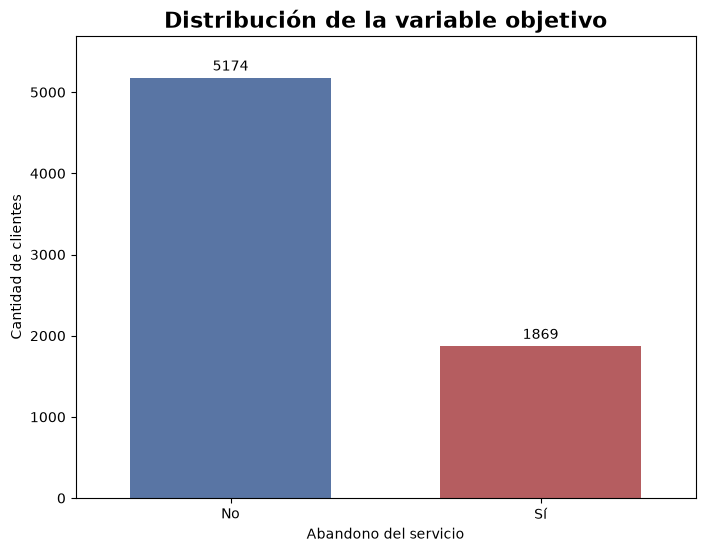

In [14]:
fig, ax = visualizaciones.graficar_distribucion_churn(df)
plt.show()

* La tasa general de churn es del **26.5%**. Veamos entonces los distintos grupos de clientes. ¿Qué grupos presentan una mayor probabilidad de abandono?

### **1.5.2 Análisis Univariado**

#### **Análisis univariado de variables numéricas**

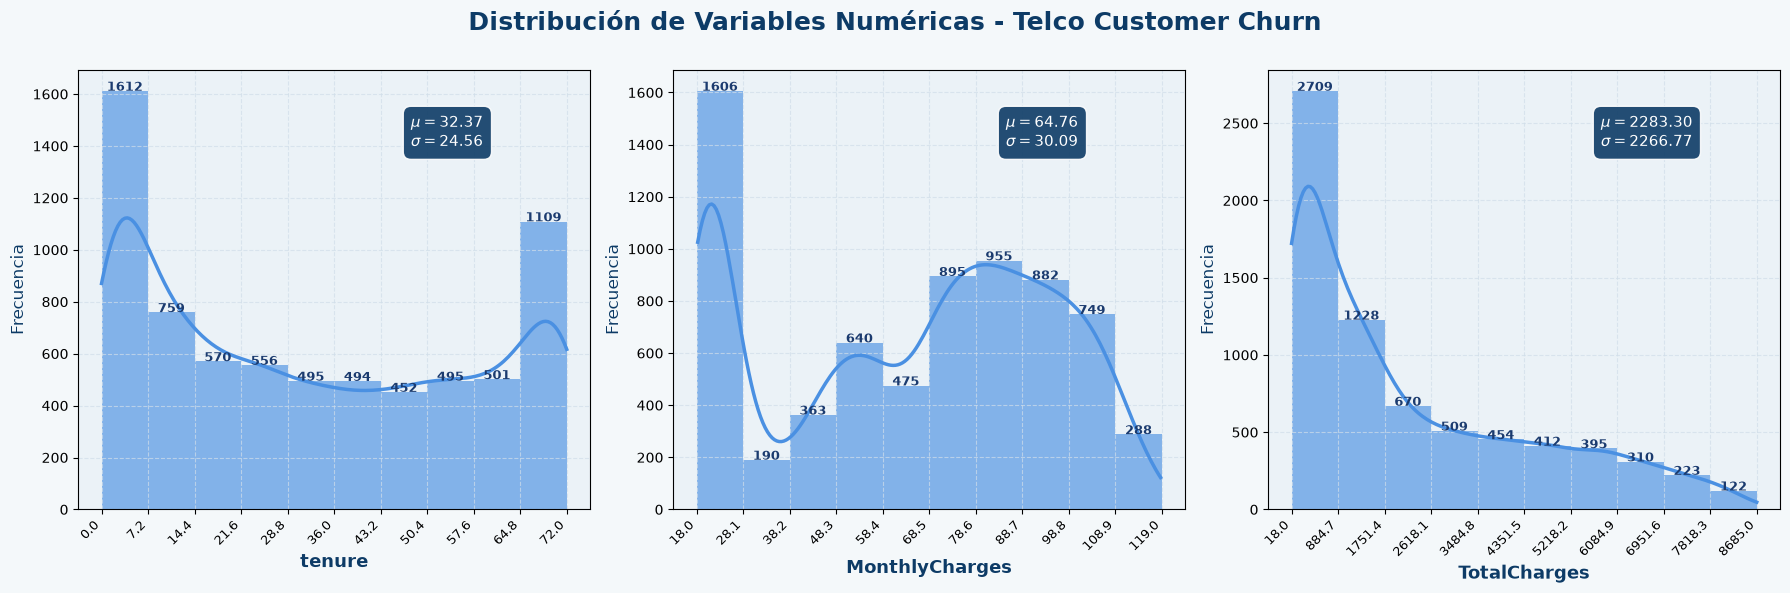

In [15]:
caracteristicas_continuas = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Filtrar características continuas para el análisis univariado
df_continuas = df[caracteristicas_continuas]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
for i, col in enumerate(df_continuas.columns):
    # Se añade dropna() preventivo, ya que TotalCharges suele tener valores nulos
    valores, bordes_bins = np.histogram(df_continuas[col].dropna(), range=(np.floor(df_continuas[col].min()), np.ceil(df_continuas[col].max())))
    
    # Gráfico con azul clínico intermedio (#4A90E2) y línea KDE en azul marino profundo (#0D3B66)
    grafico = sns.histplot(data=df_continuas, x=col, bins=bordes_bins, kde=True, ax=ax[i],edgecolor='none', color='#4A90E2', alpha=0.65, line_kws={'lw': 2.5, 'color': '#0D3B66'})
    
    ax[i].set_facecolor('#EBF2F7')
    ax[i].set_xlabel(col, fontsize=13, fontweight='bold', color='#0D3B66')
    ax[i].set_ylabel('Frecuencia', fontsize=12, color='#0D3B66')
    ax[i].set_xticks(np.round(bordes_bins, 1))
    ax[i].set_xticklabels(ax[i].get_xticks(), rotation=45, ha='right', fontsize=9)
    ax[i].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7)
    
    # Anotaciones de frecuencia sobre cada barra
    for j, p in enumerate(grafico.patches):
        altura = p.get_height()
        if altura > 0:
            ax[i].annotate(f'{int(altura)}', (p.get_x() + p.get_width() / 2, altura + 0.8),ha='center', fontsize=9, fontweight='bold',color='#1B3B6F')
    
    # Cuadro de estadísticas (media y desviación estándar) en tono azul marino clínico
    texto_estadisticas = '\n'.join((r'$\mu=%.2f$' % df_continuas[col].mean(),r'$\sigma=%.2f$' % df_continuas[col].std()))
    ax[i].text(0.65, 0.90,texto_estadisticas, transform=ax[i].transAxes, fontsize=11, verticalalignment='top',color='white', bbox=dict(boxstyle='round,pad=0.5', facecolor='#0D3B66', edgecolor='white', alpha=0.9))

fig.patch.set_facecolor('#F4F8FA')
# Título adaptado al contexto del churn
plt.suptitle('Distribución de Variables Numéricas - Telco Customer Churn', fontsize=18, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

#### **Análisis univariado de variables categóricas**

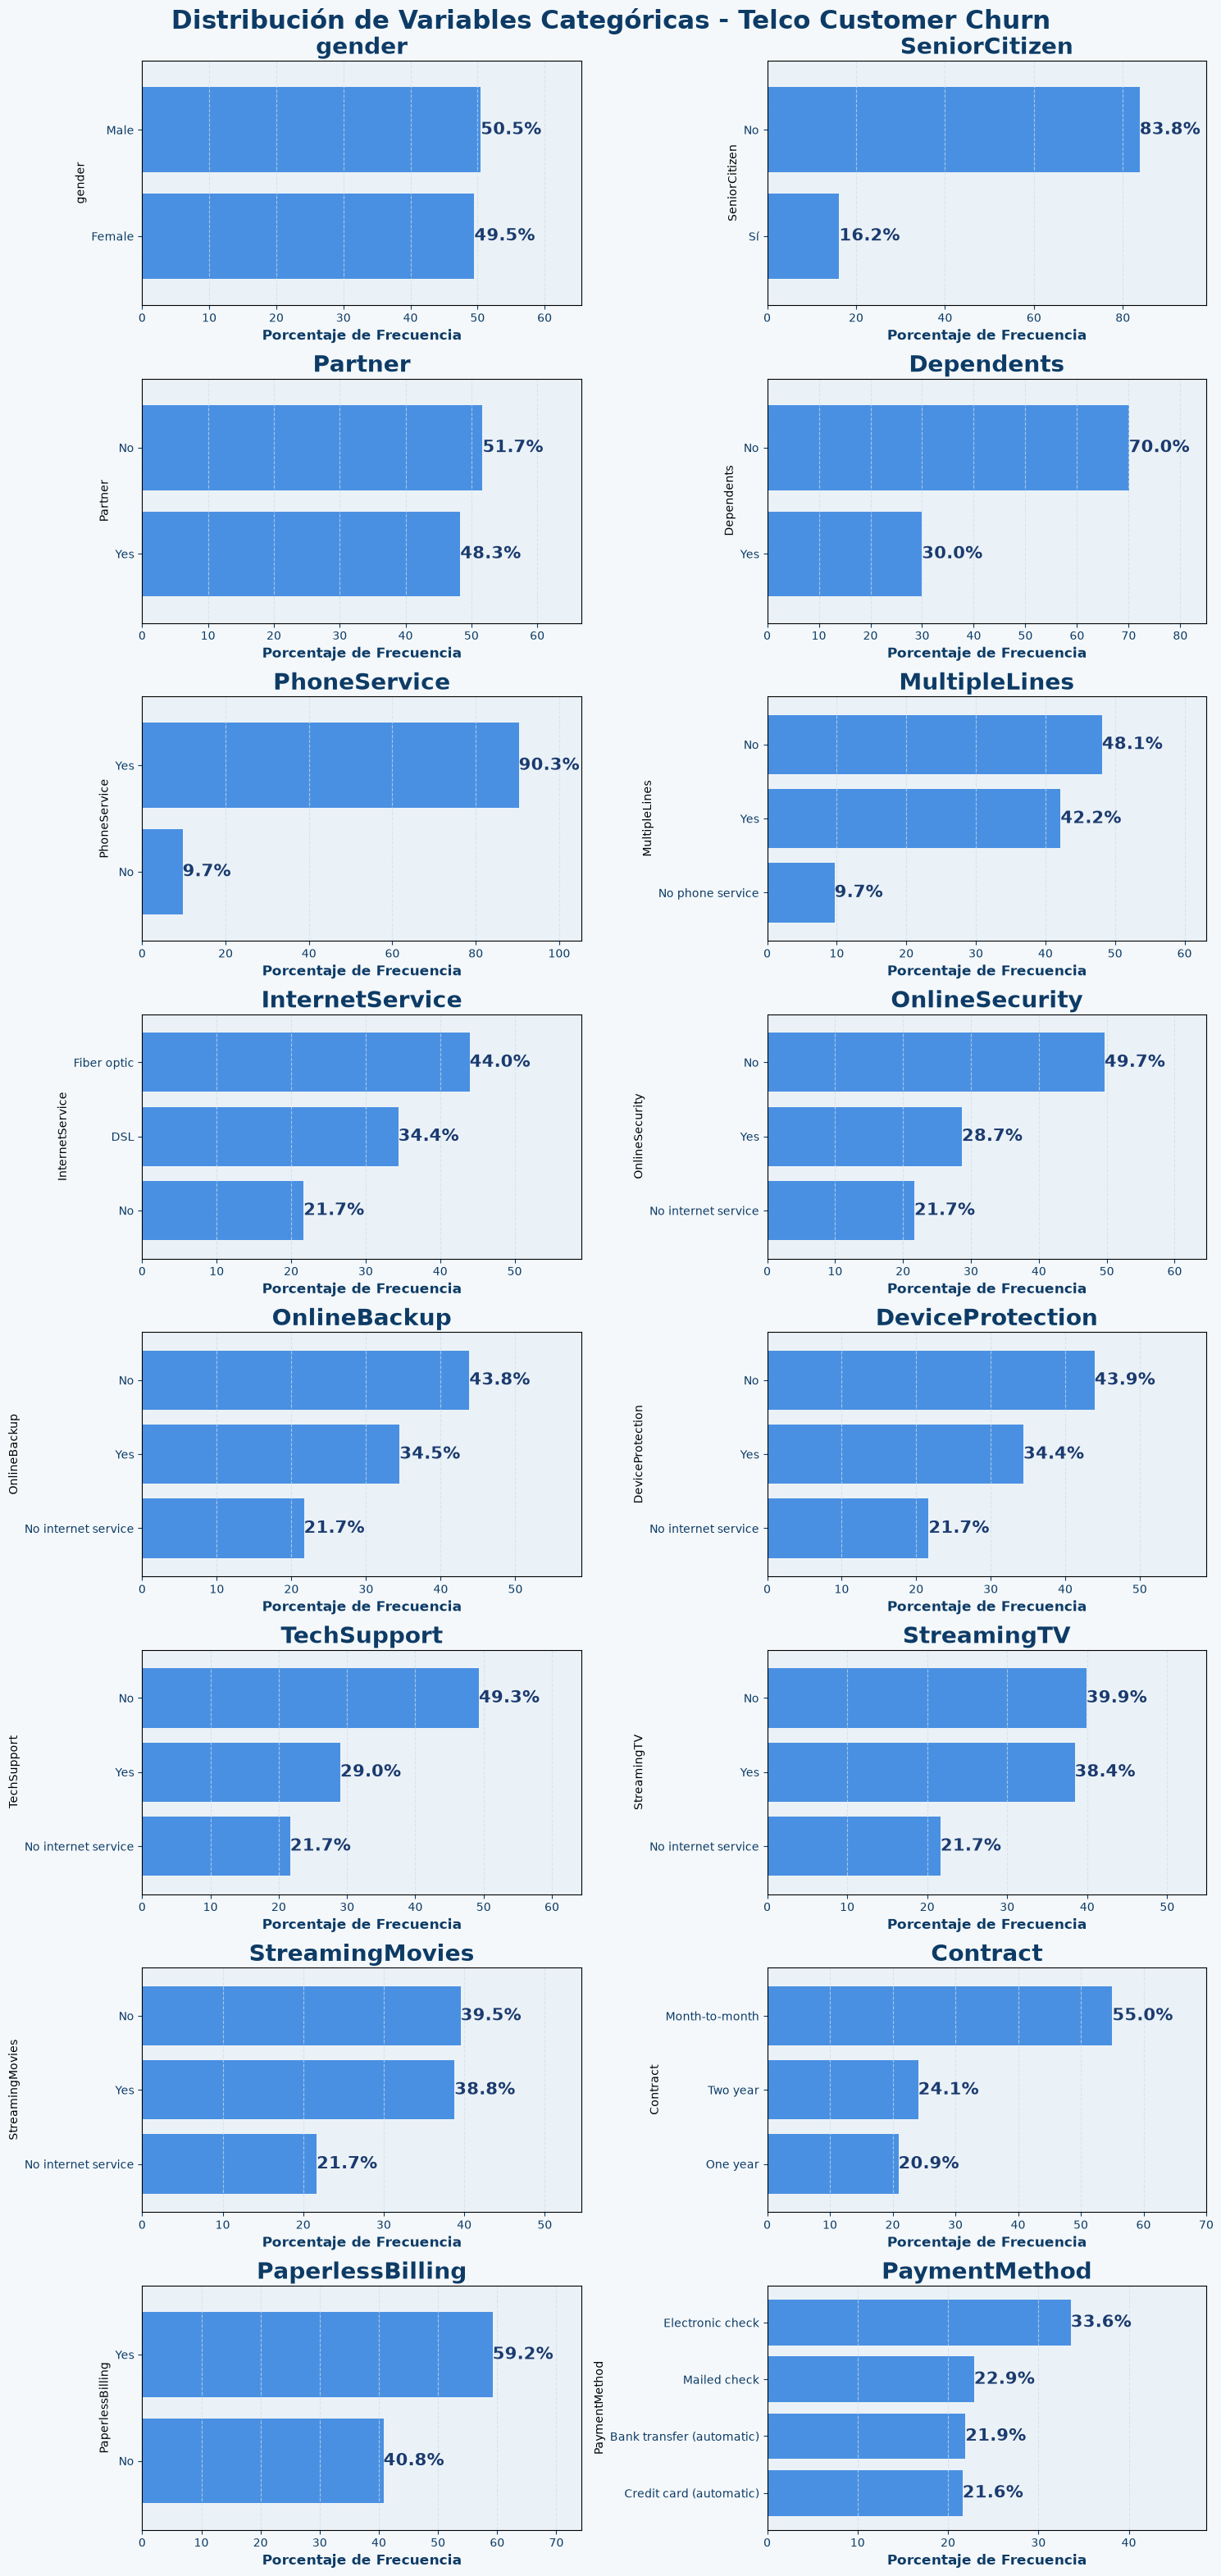

In [16]:
caracteristicas_categoricas = df.select_dtypes(include=['object', 'str']).columns.drop(['customerID_Hash', 'Churn'], errors = 'ignore')
df_categoricas = df[caracteristicas_categoricas].copy()

ncols = 2
nrows = (len(caracteristicas_categoricas) + ncols - 1) // ncols

fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 4 * nrows))
fig.patch.set_facecolor('#F4F8FA')

for i, col in enumerate(caracteristicas_categoricas):
    row = i // ncols
    col_idx = i % ncols
    
    # Calcular porcentajes de frecuencia
    conteo_valores = df[col].value_counts(normalize=True).mul(100).sort_values()
    
    # Graficar gráfico de barras
    conteo_valores.plot(kind='barh', ax=ax[row, col_idx], width=0.8, color='#4A90E2')
    
    # Configurar color de fondo del gráfico y la cuadrícula
    ax[row, col_idx].set_facecolor('#EBF2F7')
    ax[row, col_idx].grid(True, color='#D0DEE9', linestyle='--', alpha=0.7, axis='x')
    
    # Añadir porcentajes de frecuencia a las barras
    for index, value in enumerate(conteo_valores):
        ax[row, col_idx].text(value, index, str(round(value, 1)) + '%', fontsize=15, weight='bold', va='center', color='#1B3B6F')
    
    ax[row, col_idx].set_xlim([0, conteo_valores.max() + 15]) 
    ax[row, col_idx].set_xlabel('Porcentaje de Frecuencia', fontsize=12, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].set_title(f'{col}', fontsize=20, fontweight='bold', color='#0D3B66')
    ax[row, col_idx].tick_params(colors='#0D3B66')

for j in range(len(caracteristicas_categoricas), nrows * ncols):
    r = j // ncols
    c = j % ncols
    ax[r, c].axis('off')

plt.suptitle('Distribución de Variables Categóricas - Telco Customer Churn', fontsize=22, fontweight='bold', color='#0D3B66')
plt.tight_layout()
plt.subplots_adjust(top=0.96)
plt.show()

### **1.5.3 Análisis Bivariado**

#### **Características numéricas vs. Objetivo**

Para las variables numéricas, se calculan y grafican las funciones de estimación de densidad de kernel (KDE).

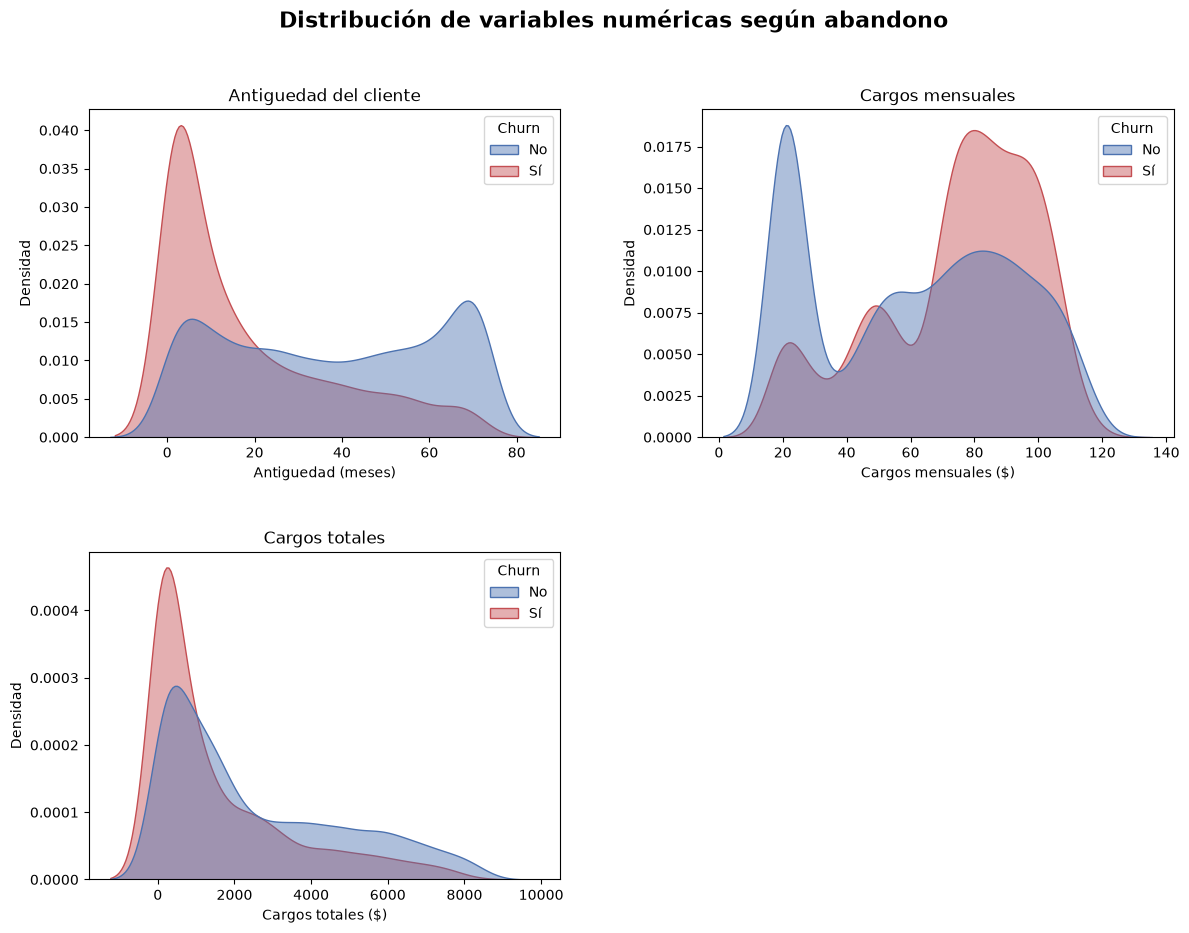

In [17]:
# generar curvas de densidad según la variable Churn
fig, axes = visualizaciones.graficar_curvas_densidad_churn(df)
plt.show()

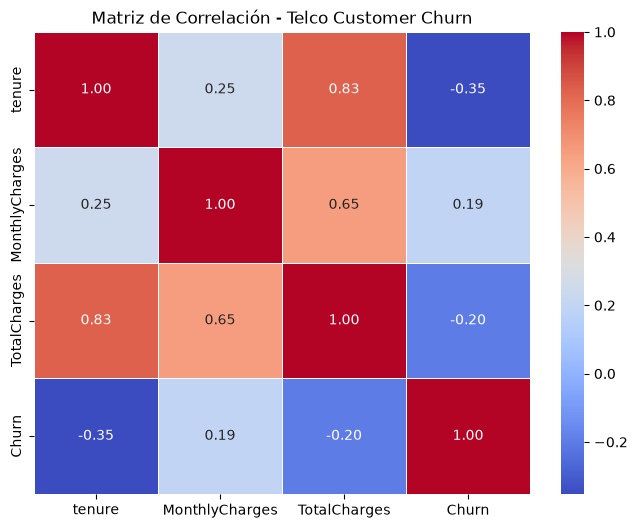

In [18]:
# mapa de calor matriz de correlaciones variables numéricas
df_copy = df.copy()
df_copy["Churn"] = df_copy["Churn"].map({"No": 0, "Yes": 1}).astype(object)
df_copy["Churn"] = pd.to_numeric(df_copy["Churn"], errors="coerce")
numeric_df = df_copy.select_dtypes(include=[np.number])
numeric_df = numeric_df.drop(columns=['customerID_Hash'], errors='ignore')
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación - Telco Customer Churn')
plt.show()

* **Antiguedad y Cargos Totales (0,825):** Fuerte correlación positiva. Como es lógico, los clientes que llevan más tiempo en la empresa acumulan un gasto total mayor.

* **Antiguedad y Cargos Mensuales (0,248):** Correlación positiva débil. Existe una ligera tendencia donde los clientes más antiguos asumen tarifas mensuales un poco más altas, lo que sugiere que podrían estar contratando servicios de mayor precio.

In [19]:
# agrupar por 'Churn' y calcular el promedio
resumen = df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(2)
tabla_churn_numeric = resumen.T
tabla_churn_numeric.columns = ['Churn = No', 'Churn = Sí']
tabla_churn_numeric

,Churn = No,Churn = Sí
tenure,37.57,17.98
MonthlyCharges,61.27,74.44
TotalCharges,2555.34,1531.80


**Observaciones:**

**Antiguedad (Meses):**

* Los clientes activos tienen una antiguedad promedio de 37,57 meses.
* Quienes cancelaron el servicio muestran una permanencia menor, con un promedio de 17,98 meses.
* A mayor tiempo en la compañía, menor es la probabilidad de abandono.
* Los clientes nuevos con poca antiguedad tienen más probabilidades de cambiar de compañía.

**Cargos Mensuales:**

* El pago mensual promedio de los clientes activos es de $61,27.
* Quienes se dieron de baja pagaban una tarifa un poco mayor, cercana a los $74,44.
* Los clientes que pagan cargos mensuales más altos también tienen más probabilidades de cancelar el servicio.

**Cargos Totales:**

* Los clientes que mantienen su suscripción acumulan un promedio de $2554,77 en cargos totales.
* Quienes cancelaron el servicio acumularon un gasto inferior, de alrededor de $1531,80.
* Los usuarios con un mayor gasto total acumulado en el tiempo son más propensos a quedarse en la empresa.

#### **Características categóricas vs. Objetivo**

Para las variables categóricas, los gráficos de barras muestran las diferencias entre los grupos objetivo.

##### **Información de Clientes**

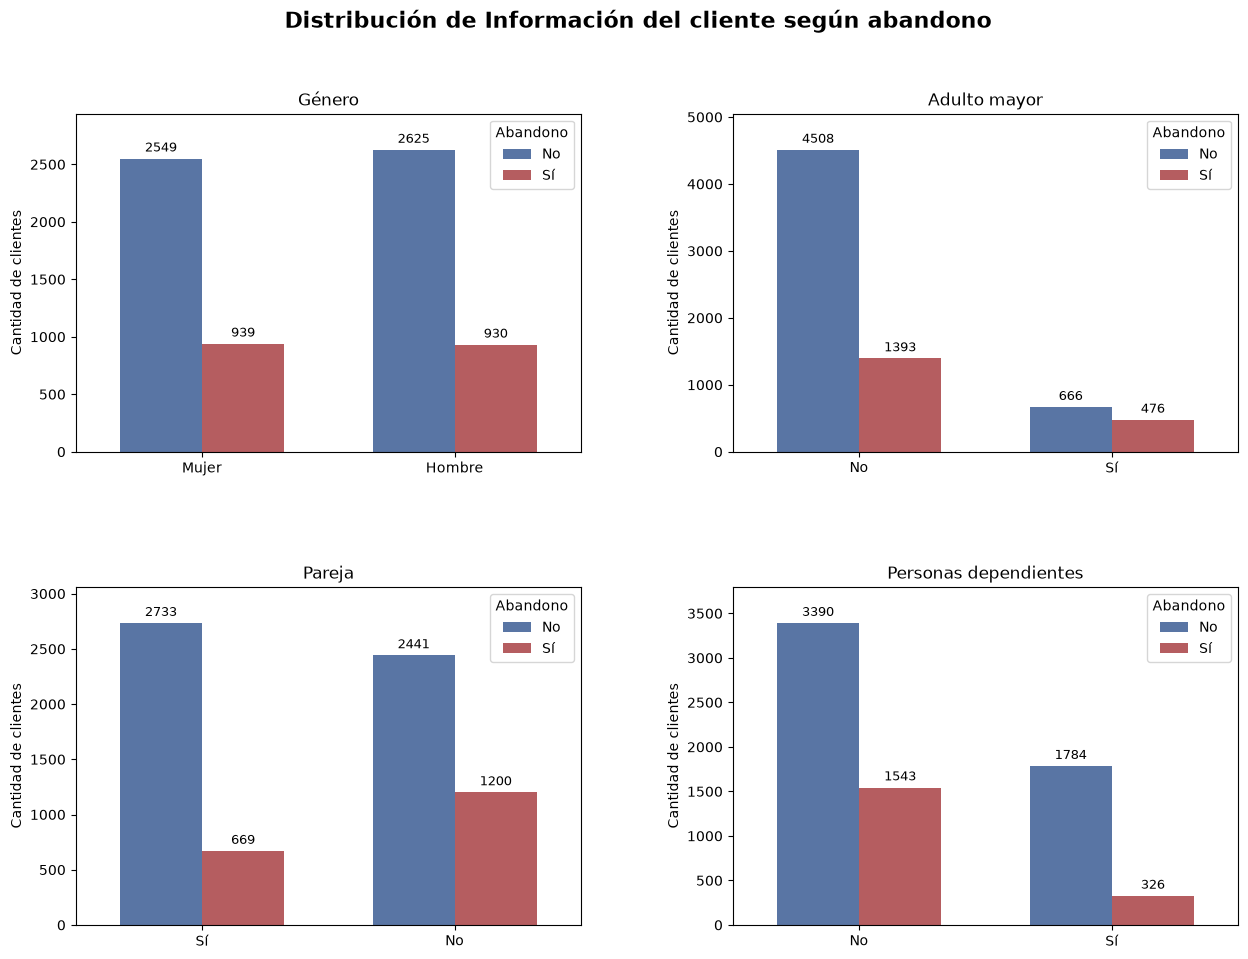

In [20]:
figura_cliente = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Información del cliente",
)
display(figura_cliente)
plt.close(figura_cliente)

* La cantidad de cancelaciones es muy similar entre clientes hombres y mujeres, sin presentar una diferencia importante.
* Clientes sin pareja y clientes sin familiares (dependientes), así como los adultos mayores en proporción tiene mayor probabilidad de abandono.
* La mayor parte de los clientes que son adultos mayores termina cancelando su servicio.

##### **Servicios Contratados**

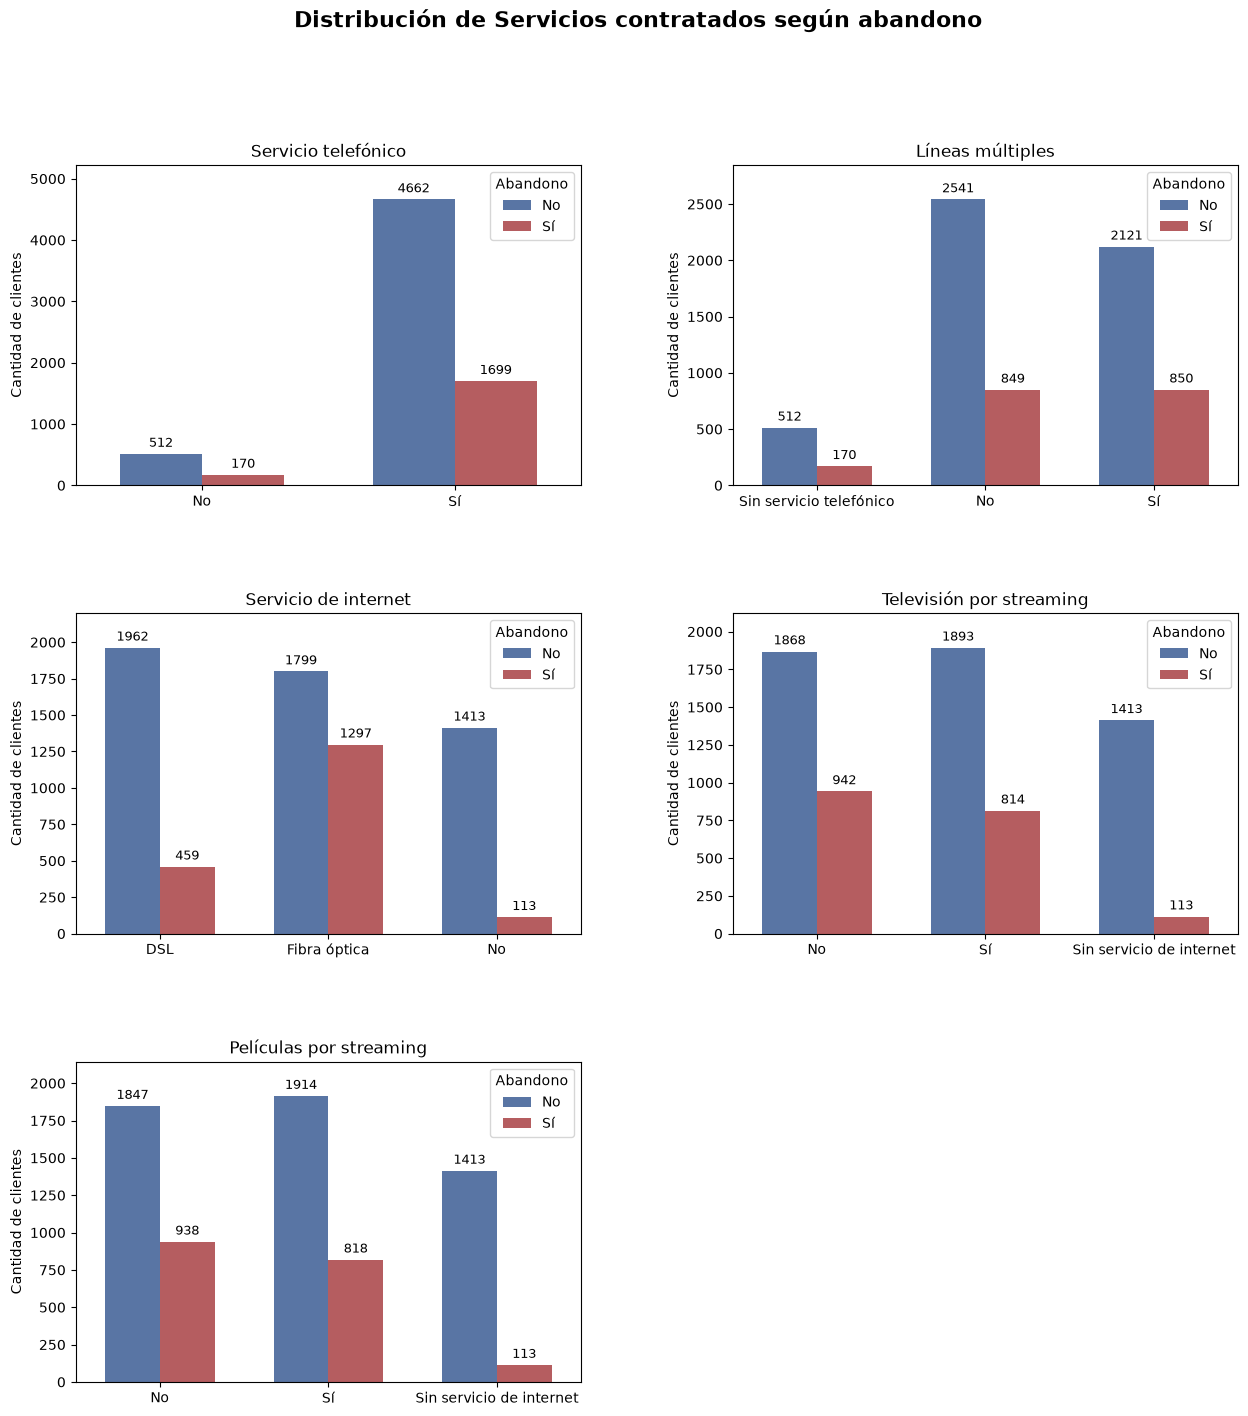

In [21]:
figura_servicios = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Servicios contratados"
)
display(figura_servicios)
plt.close(figura_servicios)

* Un alto número de clientes con internet de fibra óptica cancelaron su servicio.
* Los usuarios con conexión DSL abandonan la compañía con menor frecuencia.
* Los clientes que no cuentan con servicio de internet presentan una tasa de abandono muy baja.
* Una gran parte de los clientes elige el servicio de fibra óptica, pero presentan una alta tasa de abandono, lo que sugiere una posible insatisfacción con este tipo de conexión.

##### **Seguridad y soporte**

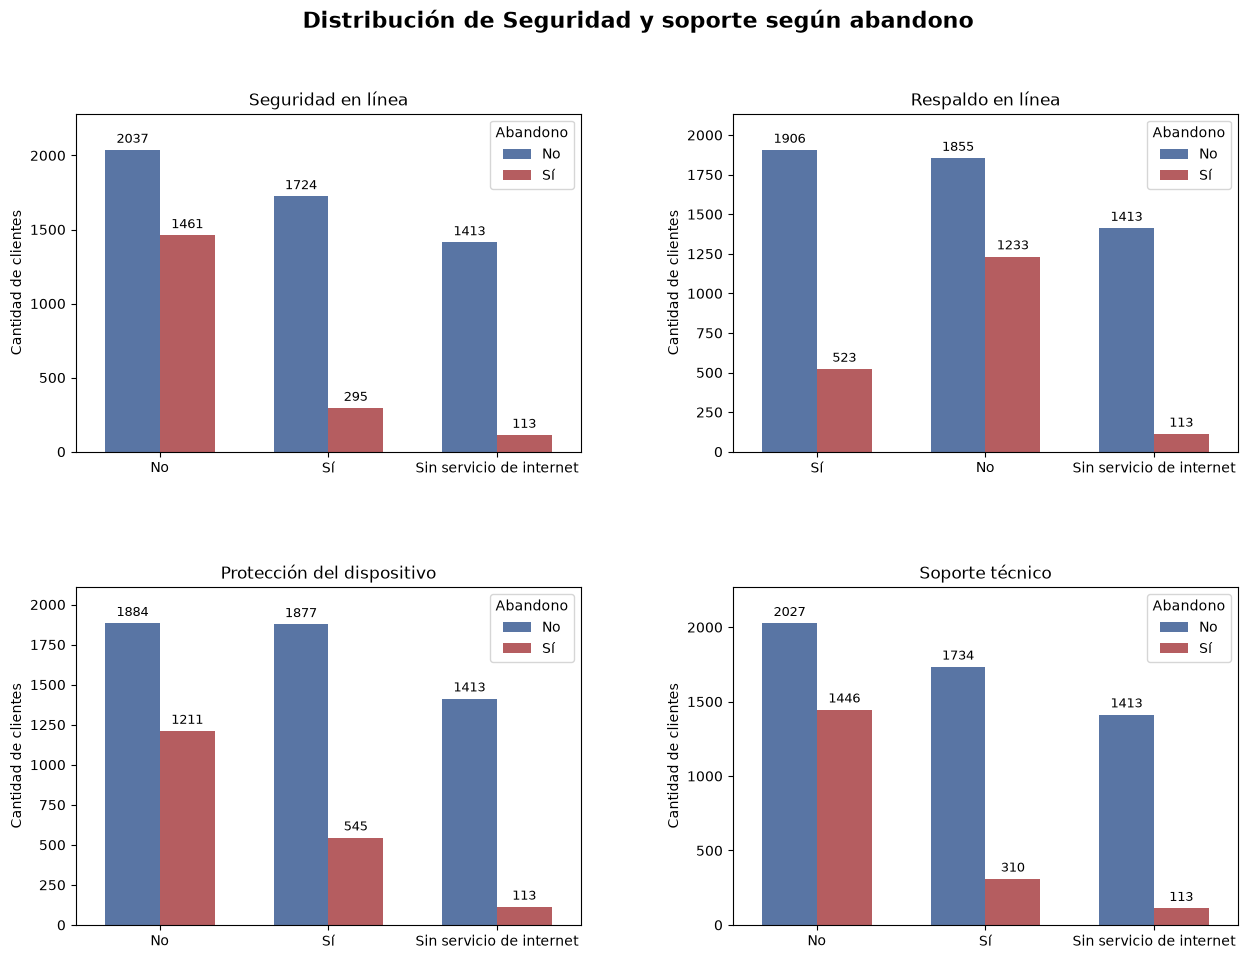

In [22]:
figura_seguridad = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Seguridad y soporte"
)
display(figura_seguridad)
plt.close(figura_seguridad)

* Seguridad en línea y Soporte técnico son los servicios que más protegen la retención, bajando el abandono de un 42% (clientes sin el servicio) a solo un 15% (clientes con el servicio).
* Respaldo y Protección del dispositivo también muestran un impacto positivo logrando reducir el nivel de fuga de un 40% a un 22%.
* Los clientes que contrataron servicios de seguridad o soporte técnico adicional tienen menos probabilidades de cancelar su servicio. Resulta clave ofrecer promociones que incluyan seguridad o soporte técnico.

##### **Información de Pago**

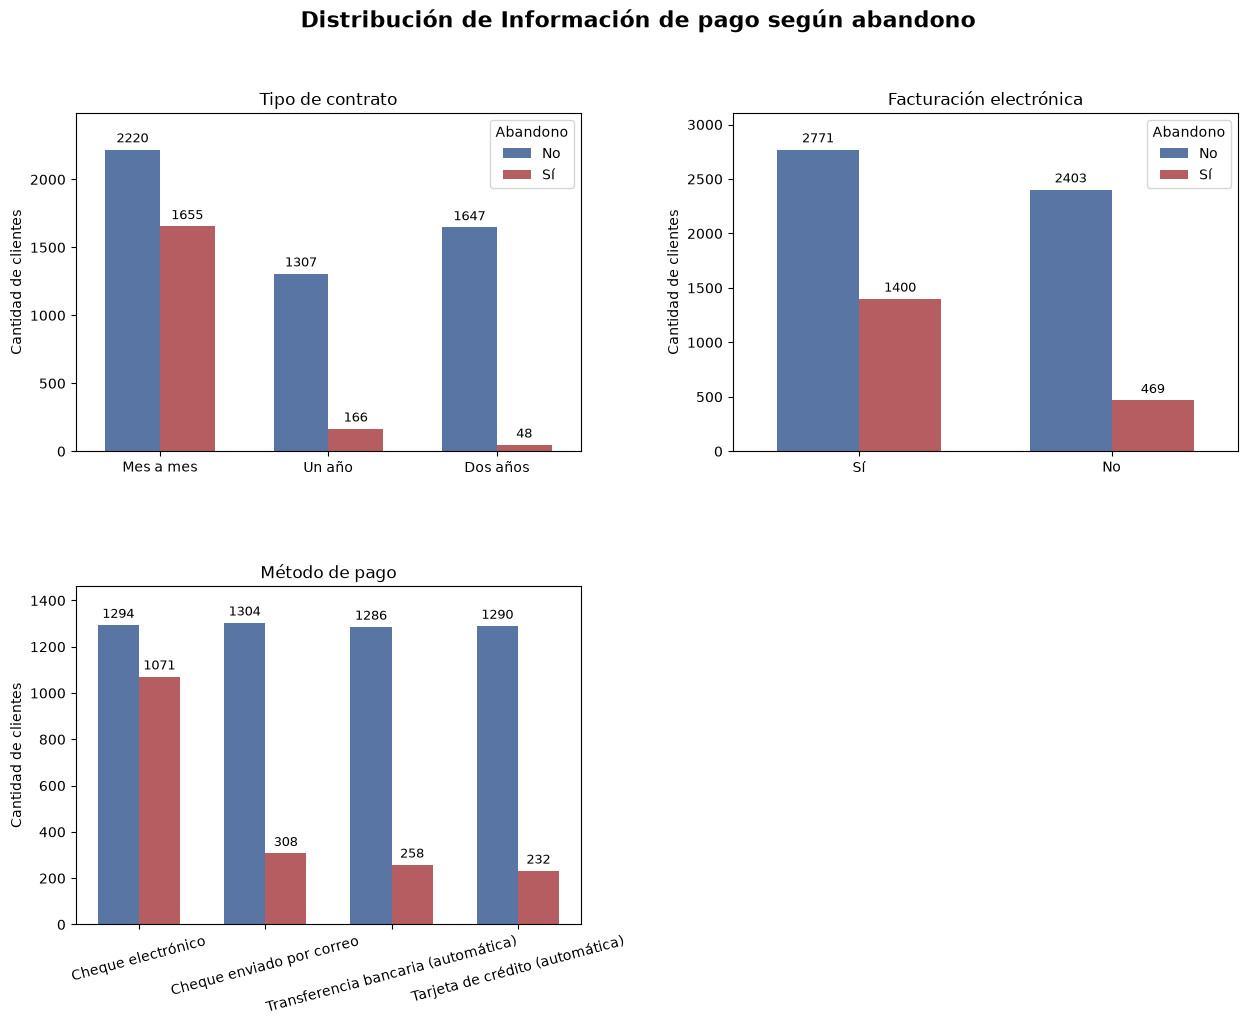

In [23]:
figura_pago = visualizaciones.graficar_grupo_categorico_churn(
    df,
    nombre_grupo="Información de pago"
)
display(figura_pago)
plt.close(figura_pago)

* El abandono es crítico en la modalidad "Mes a mes" (42.7%), pero disminuye drásticamente en compromisos de "Un año" (11.2%) y "Dos años" (2.8%).
* Los clientes con facturación electrónica presentan el doble de tasa de abandono (33.5%) que aquellos con facturación tradicional (16.3%).
* El "Cheque electrónico" es el método de mayor riesgo con un 45.2% de fuga, mientras que las otras alternativas promedian un abandono mucho menor (15-19%).


* Es prioritario incentivar contratos largos. Ofrecer beneficios para que los clientes mensuales pasen a planes anuales o de dos años, donde la tasa de abandono es casi nula.
* Se sugiere revisar el cheque electrónico. Es importante investigar por qué este método genera tantas cancelaciones y sugerir activamente a los clientes que cambien al pago automático.
* Se debe fidelizar al cliente digital. Ya que la facturación electrónica facilita la cancelación, necesitamos buscar nuevas formas de recordarles el valor del servicio para que decidan quedarse.



##### **Correlaciones de variables categóricas con Churn**

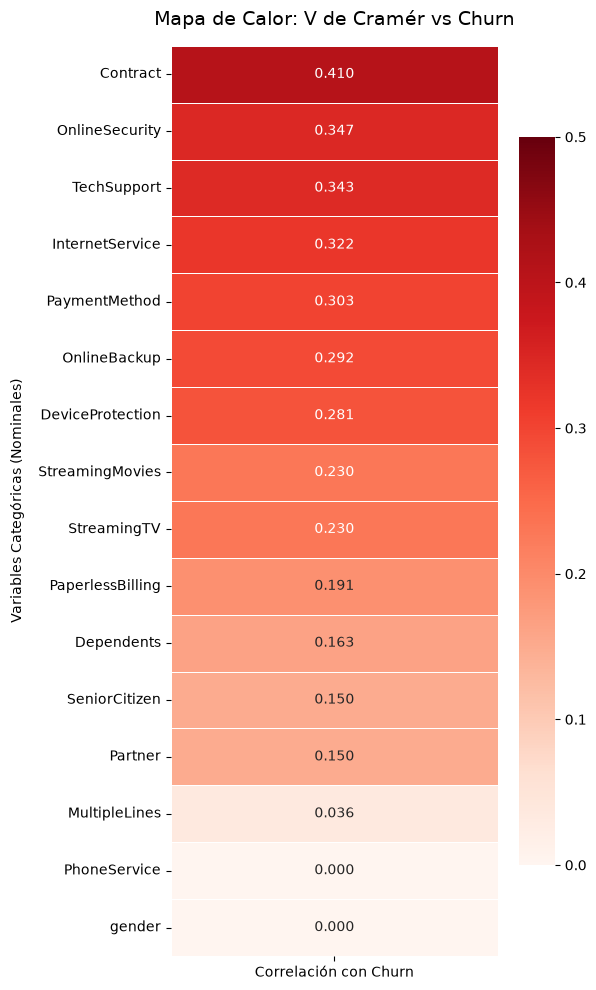

In [24]:
# Identificar las columnas categóricas
cat_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

# Excluir las columnas que no se utilizarán en la codificación
for col in ['customerID_Hash', 'Churn']:
    if col in cat_cols:
        cat_cols.remove(col)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = ss.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape

    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r- ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)

    min_denom = min((kcorr-1), (rcorr-1))
    if min_denom == 0:
        return 1.0 
    return np.sqrt(phi2corr / min_denom)

churn_corr = {}
for col in cat_cols:
    churn_corr[col] = cramers_v(df[col], df['Churn'])

corr_df = pd.DataFrame.from_dict(churn_corr, orient='index', columns=['Correlación con Churn'])
corr_df = corr_df.sort_values(by='Correlación con Churn', ascending=False)

plt.figure(figsize=(6, 10))
sns.heatmap(
    corr_df, 
    annot=True, 
    cmap='Reds',      # Escala de rojos para advertir riesgo de abandono
    fmt=".3f", 
    linewidths=.5, 
    vmin=0, 
    vmax=0.5,         # Ajustar el máximo a 0.5 resalta el contraste del bloque superior
    cbar_kws={"shrink": .8}
)
plt.title("Mapa de Calor: V de Cramér vs Churn", fontsize=14, pad=15)
plt.ylabel("Variables Categóricas (Nominales)", labelpad=10)
plt.tight_layout()
plt.show()

# **2. Preparación de los Datos para Machine Learning**

## **2.1 Análisis de Completitud**

In [25]:
# conteo de valores nulos por columna
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
customerID_Hash      0
dtype: int64

* La columna **TotalCharges** tienen algunos valores faltantes

In [26]:
# muestra registros con valores nulos en TotalCharges
df[np.isnan(df['TotalCharges'])]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
488,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,...,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,3fc827a9c771a5597e1b9563ba46bd77b5a33daad5f094...
753,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No,cc8dcc067e61d7292f35e1d99cf280c8f1663b1d6b9dc0...
936,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,...,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,58d283200bed248b5d1e0eb621b905ecbb502854900fb3...
1082,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,ea0b24cc08647ff604fd33a68453a8adb51fdc83f96386...
1340,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,...,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0e9341d2f088bdb7928f46db857c21c35c9eaafb56084d...
3331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,8c6c0d363aa75ea0795734b32d5adcbbd77845674cc04e...
3826,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,f3d447e5d65b5d31443dae3b897268f29b906c53a3bb29...
4380,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,3c63ffbaff09f452804dc16726922dfddfb6354320fd79...
5218,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No,01b32519075edcfd0f091c271f6cc693e2ed154b5a38c9...
6670,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,...,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,53819de429be29e2cf2d830bf81fd95987cea3db3612ce...


* En los registros donde **TotalCharges** presenta valores nulos, la antiguedad del cliente (**tenure**) es igual a 0. Por este motivo, y dado que la baja cantidad de valores faltantes no afectará la calidad del conjunto, es seguro reemplazar dichos valores faltantes por 0

In [27]:
# reemplazar valores nulos de TotalCharges por 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Valores nulos de TotalCharges reemplazados por 0.")

Valores nulos de TotalCharges reemplazados por 0.


## **2.2 Análisis de Duplicidad**

In [28]:
# registros duplicados
print(f"Cantidad de registros duplicados: {df.duplicated().sum()}")

Cantidad de registros duplicados: 0


* Tras la revisión, no se encontraron valores duplicados en el conjunto de datos

## **2.3 Análisis de valores atípicos**

In [29]:
# buscar valores atípicos usando el rango intercuartil
columnas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

for columna in columnas_numericas:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    rango_intercuartil = q3 - q1

    limite_inferior = q1 - 1.5 * rango_intercuartil
    limite_superior = q3 + 1.5 * rango_intercuartil

    valores_atipicos = df[
        (df[columna] < limite_inferior) | (df[columna] > limite_superior)
    ]

    if len(valores_atipicos) > 0:
        print(f"{columna}: sí presenta valores atípicos ({len(valores_atipicos)} registros).")
    else:
        print(f"{columna}: no presenta valores atípicos.")

tenure: no presenta valores atípicos.
MonthlyCharges: no presenta valores atípicos.
TotalCharges: no presenta valores atípicos.


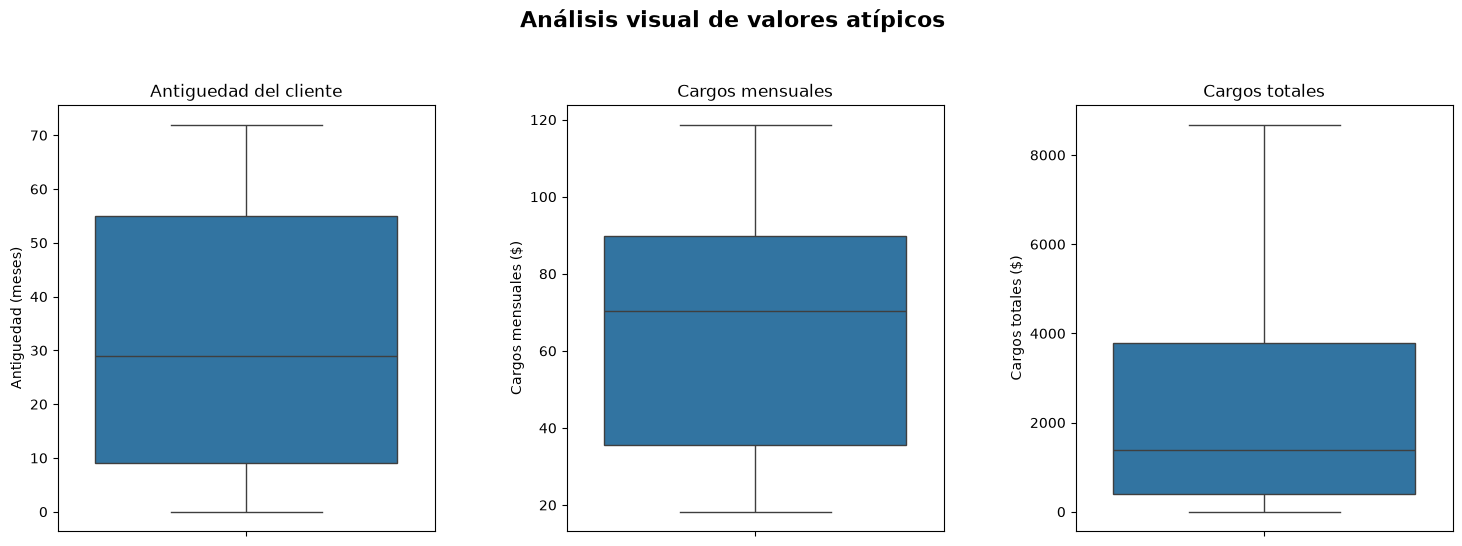

In [30]:
# crear una figura con múltiples espacios
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Análisis visual de valores atípicos", fontsize=16, fontweight="bold")

# dibujar cada gráfico de caja con nombres descriptivos en español
sns.boxplot(y=df["tenure"], ax=axes[0])
axes[0].set_title("Antiguedad del cliente")
axes[0].set_xlabel("")
axes[0].set_ylabel("Antiguedad (meses)")

sns.boxplot(y=df["MonthlyCharges"], ax=axes[1])
axes[1].set_title("Cargos mensuales")
axes[1].set_xlabel("")
axes[1].set_ylabel("Cargos mensuales ($)")

sns.boxplot(y=df["TotalCharges"], ax=axes[2])
axes[2].set_title("Cargos totales")
axes[2].set_xlabel("")
axes[2].set_ylabel("Cargos totales ($)")

plt.subplots_adjust(wspace=0.35, top=0.82)
plt.show()

* No se encontraron valores atípicos en las variables numéricas analizadas

## **2.4 Codificación de características categóricas**

## **2.5 Evaluación del Escalado de Características**

# **3. Construcción y Evaluación de Modelos**

In [31]:
# Crear una copia de referencia del dataset para la implementación de modelos
df_base_modelos = df.copy(deep=True)

# Crear datasets independientes para cada tipo de aprendizaje
df_clasificacion = df_base_modelos.copy(deep=True)
df_regresion = df_base_modelos.copy(deep=True)
df_segmentacion = df_base_modelos.copy(deep=True)

In [32]:
df_clasificacion

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5f362546eb7515f442a40d3d9bf632e4a481c92bcb0529...
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,701bf78bdf332d16ec5fb80a1affac3a080a8b9c258c2d...
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,59a0e1b332a6b6ba8f6a72f74085e6498e8c54a5d18191...
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,66370db9e1bb6a851fa692a2499f4f1356efab8e5abf90...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,d947cded0fac0a00ebc313bbe4c4b64e23283d0cf7b536...
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,cb985e07827c720145c2de03810a8ec565fe1121c0b6bd...
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,32b725664afc96d8366d2d44ffb7a801132d3f84d68c19...
7041,Male,Sí,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,b8463bcb56ddf1b47ee63bafdf65079f88d260b99ccd89...


In [33]:
df_regresion

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5f362546eb7515f442a40d3d9bf632e4a481c92bcb0529...
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,701bf78bdf332d16ec5fb80a1affac3a080a8b9c258c2d...
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,59a0e1b332a6b6ba8f6a72f74085e6498e8c54a5d18191...
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,66370db9e1bb6a851fa692a2499f4f1356efab8e5abf90...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,d947cded0fac0a00ebc313bbe4c4b64e23283d0cf7b536...
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,cb985e07827c720145c2de03810a8ec565fe1121c0b6bd...
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,32b725664afc96d8366d2d44ffb7a801132d3f84d68c19...
7041,Male,Sí,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,b8463bcb56ddf1b47ee63bafdf65079f88d260b99ccd89...


In [34]:
df_segmentacion

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,customerID_Hash
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,f3f9002e121cbbcc038f195a656a32a17395c6ce1815e8...
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,5f362546eb7515f442a40d3d9bf632e4a481c92bcb0529...
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,701bf78bdf332d16ec5fb80a1affac3a080a8b9c258c2d...
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,59a0e1b332a6b6ba8f6a72f74085e6498e8c54a5d18191...
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,66370db9e1bb6a851fa692a2499f4f1356efab8e5abf90...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,...,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No,d947cded0fac0a00ebc313bbe4c4b64e23283d0cf7b536...
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No,cb985e07827c720145c2de03810a8ec565fe1121c0b6bd...
7040,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,32b725664afc96d8366d2d44ffb7a801132d3f84d68c19...
7041,Male,Sí,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes,b8463bcb56ddf1b47ee63bafdf65079f88d260b99ccd89...


## **3.1 Aprendizaje Supervisado: Modelos de Clasificación**

### **3.1.1 Selección y Conservación de Características**

Construcción de listados para preprocesamiento

In [35]:
# Características numéricas para clasificación
numericas_clf = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'Aumento_Tarifa',
    'Total_Servicios_Extra'
]

# Características categóricas binarias
categoricas_binarias_clf = [
    'PaperlessBilling',
    'Pago_Automatico',
    'Vive_Solo',
    'Perfil_Alto_Riesgo'
]

# Características categóricas nominales
categoricas_nominales_clf = [
    'InternetService'
]

# Características categóricas ordinales
categoricas_ordinales_clf = [
    'Contract'
]

jerarquia_contrato_clf = [
    ['Month-to-month', 'One year', 'Two year']
]

In [36]:
# Transformar la variable objetivo únicamente en el dataset de clasificación
df_clasificacion["Churn"] = (
    df_clasificacion["Churn"]
    .map({"No": 0, "Yes": 1})
    .astype("int8")
)

* Manipulamos el formato de los valores de la variable objetivo para que el modelo interprete de mejor manera. YES/NO -> 1/0

### **3.1.2 Modelo de Regresión Logística**

*   **Transformaciones específicas:** Usamos el pipeline numérico base (escalamiento con `MinMaxScaler`), paso vital porque este algoritmo es muy sensible a los valores extremos y a las diferencias de escala.
*   **Configuración del modelo:** Aplicamos `LogisticRegression` con `max_iter=1000`, clases balanceadas (`class_weight='balanced'`)

#### **Pipelines de Transformación**


Se implementan pipelines de transformación numérica y categórica, se crea un transformador personalizado (`TelcoFeatureEngineer`) para generar variables clave, y se divide el dataset estratificando la variable objetivo (80% entrenamiento / 20% prueba).

In [37]:
pipeline_numerico_clf = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ('scaler', MinMaxScaler())
])

pipeline_categorico_nominal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False)
    )
])

pipeline_categorico_binario = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

pipeline_categorico_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(categories=jerarquia_contrato_clf, handle_unknown='use_encoded_value', unknown_value=-1))
])
    
pipeline_preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_clf, numericas_clf),
        ("cat_nom", pipeline_categorico_nominal, categoricas_nominales_clf),
        ("cat_bin", pipeline_categorico_binario, categoricas_binarias_clf),
        ("cat_ord", pipeline_categorico_ordinal, categoricas_ordinales_clf)
    ],
    remainder="drop"
)

#### **Pipeline de Modelo LR**

In [38]:
pipeline_final_lr = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor)),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        random_state=42
    ))
])

#### **División de los Datos**

In [39]:
# Separar características predictoras y variable objetivo
X_clf = df_clasificacion.drop(
    columns=['Churn', 'customerID_Hash']
)

y_clf = df_clasificacion['Churn']

# División de entrenamiento y prueba
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    stratify=y_clf,
    random_state=42
)

#### **Entrenamiento y Evaluación LR**

In [40]:
pipeline_final_lr.fit(X_clf_train, y_clf_train)

y_pred = pipeline_final_lr.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.902,0.695,0.785,1035.00
1,0.484,0.791,0.600,374.00
accuracy,0.720,0.720,0.720,0.72
macro avg,0.693,0.743,0.693,1409.00
weighted avg,0.791,0.720,0.736,1409.00


El modelo logró una Exactitud del 72.2%. Como muestran los gráficos generados, identificó correctamente 296 fugas (Verdaderos Positivos), reduciendo los Falsos Negativos a 78 clientes no detectados. A cambio, generó 313 Falsos Positivos. La curva ROC respalda este rendimiento con un AUC de 0.831, demostrando una buena capacidad general para separar las clases.

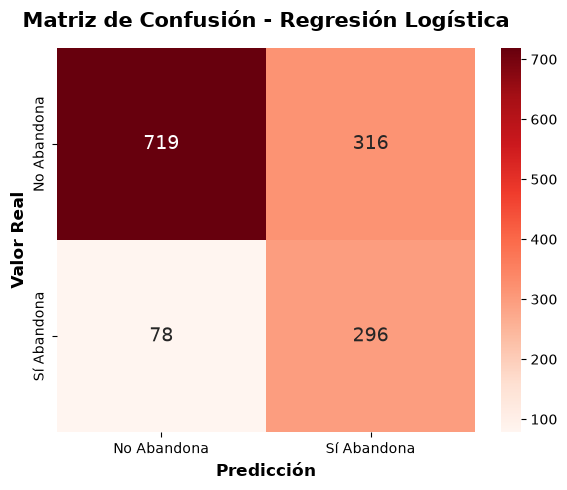

In [41]:
# Graficar Matriz de confusión para modelo de Regresión Logística
plot_matriz_confusion(y_clf_test, y_pred, nombre_modelo="Regresión Logística")

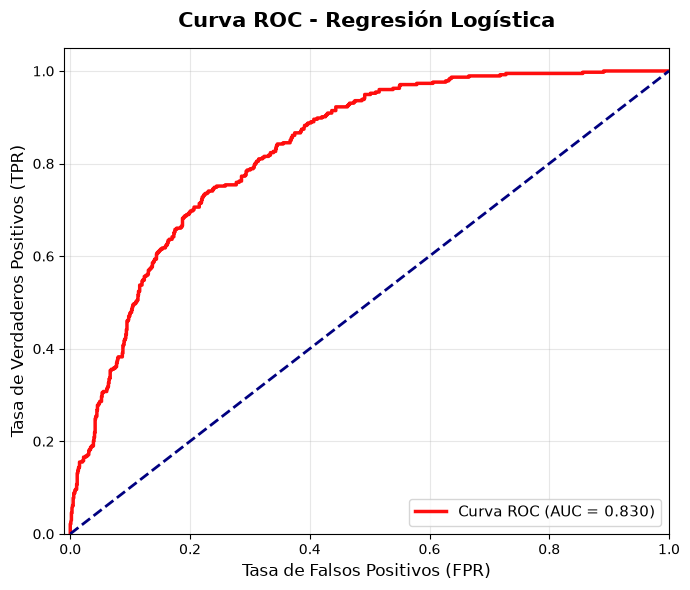

In [42]:
# Grafica Curva ROC para modelo de Regresión Logística
y_test_proba = pipeline_final_lr.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_test_proba, nombre_modelo="Regresión Logística")

### **3.1.3 Modelo de Máquinas de Vectores de Soporte (SVM)**

*   **Transformaciones específicas:** Se incluye el escalamiento numérico (`MinMaxScaler`), obligatorio para SVM porque se basa en calcular distancias.
*   **Configuración del modelo:** Usamos `SVC` con un kernel radial (`kernel='rbf'`), cálculo de probabilidades activado para generar la curva ROC y clases balanceadas.

#### **Pipeline del Modelo SVM**

In [43]:
# Pipeline base de SVM
pipeline_base_svm = Pipeline(steps=[
    ('ingenieria_caracteristicas',
     TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor)),
    ('modelo', SVC(kernel='rbf',class_weight='balanced',random_state=42))
])

# Pipeline SVM con calibración de probabilidades
pipeline_final_svm = CalibratedClassifierCV(
    estimator=pipeline_base_svm,
    method='sigmoid',
    cv=5,
    ensemble=False
)

#### **Entrenamiento y Evaluación SVM**

In [44]:
# Entrenamiento y predicción
pipeline_final_svm.fit(X_clf_train, y_clf_train)

y_pred_svm = pipeline_final_svm.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_svm, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.879,0.783,0.828,1035.000
1,0.539,0.703,0.610,374.000
accuracy,0.762,0.762,0.762,0.762
macro avg,0.709,0.743,0.719,1409.000
weighted avg,0.789,0.762,0.770,1409.000


Obtuvo la Exactitud más alta (73.4%). Sin embargo, la matriz de confusión revela que es peor para la retención: identificó 287 fugas, pero dejó escapar 87 Falsos Negativos (clientes que se van sin ser detectados), sumado a 288 Falsos Positivos. Su AUC de 0.813 confirma que predice bien, pero separa un poco peor las clases que la Regresión Logística.

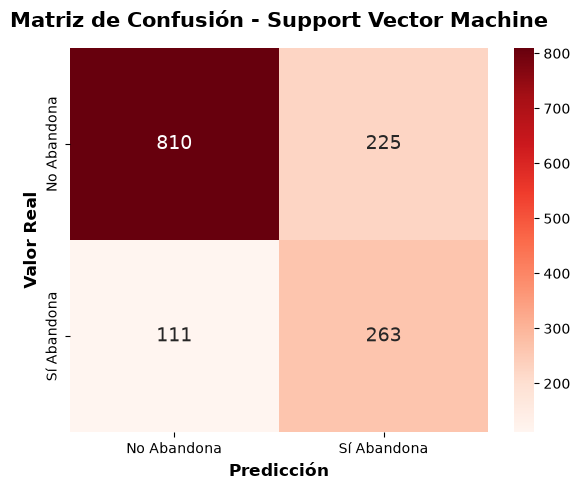

In [45]:
# Visualizaciones
plot_matriz_confusion(y_clf_test, y_pred_svm, nombre_modelo="Support Vector Machine")

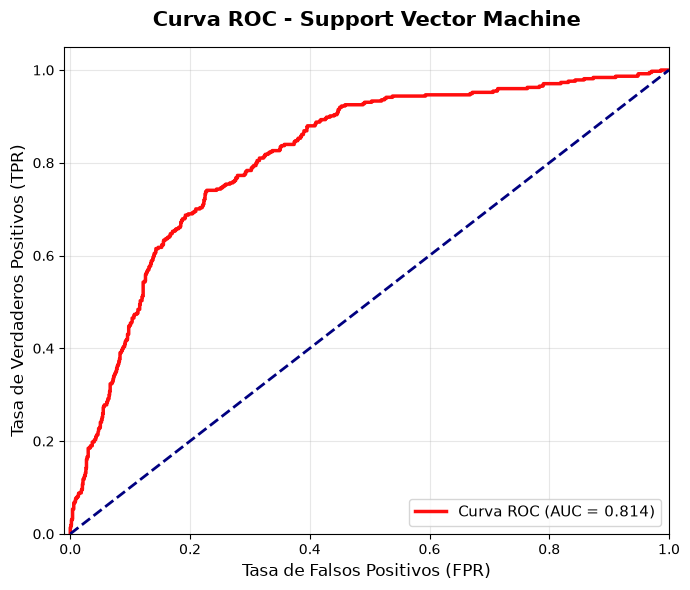

In [46]:
y_proba_svm = pipeline_final_svm.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_svm, nombre_modelo="Support Vector Machine")

### **3.1.3 Modelo de Árbol de Decisión (DecisionTreeClassifier)**

*   **Transformaciones específicas:** Usamos un pipeline independiente que solo rellena nulos (`SimpleImputer`). No se aplicó escalamiento ni manejo de atípicos porque a los árboles (basados en reglas lógicas) no les afecta la escala.
*   **Configuración del modelo:** Se limitó la profundidad a 5 niveles (`max_depth=5`) para evitar el sobreajuste, conservando el peso balanceado.

In [47]:
# pipeline numérico sin escalamiento ni tratamiento de outliers
pipeline_numerico_arbol = Pipeline([
    ("imputer", SimpleImputer(strategy="mean"))
])

pipeline_preprocessor_arbol = ColumnTransformer(
    transformers=[
        ("num", pipeline_numerico_arbol, numericas_clf),
        ("cat_nom", pipeline_categorico_nominal, categoricas_nominales_clf),
        ("cat_bin", pipeline_categorico_binario, categoricas_binarias_clf),
        ("cat_ord", pipeline_categorico_ordinal, categoricas_ordinales_clf)
    ],
    remainder="drop"
)

#### **Pipeline del Modelo DTC**

In [48]:
pipeline_final_dtc = Pipeline(steps=[
    ('ingenieria_caracteristicas', TelcoFeatureEngineer(drop_original=True, drop_addons=True)),
    ('preprocesador', clone(pipeline_preprocessor_arbol)),
    ('modelo', DecisionTreeClassifier(
        class_weight='balanced', 
        max_depth = 5,
        random_state=42
    ))
])

In [49]:
# Entrenamiento y predicción
pipeline_final_dtc.fit(X_clf_train, y_clf_train)

y_pred_dtc = pipeline_final_dtc.predict(X_clf_test)

reporte = classification_report(y_clf_test, y_pred_dtc, output_dict=True)
df_reporte = pd.DataFrame(reporte).transpose().round(3)
display(df_reporte)

,precision,recall,f1-score,support
0,0.913,0.672,0.775,1035.000
1,0.476,0.824,0.603,374.000
accuracy,0.713,0.713,0.713,0.713
macro avg,0.695,0.748,0.689,1409.000
weighted avg,0.797,0.713,0.729,1409.000


Logró la Exactitud general más baja (71.3%), pero destacó consiguiendo el Recall más alto (0.824). Como se observa arriba, detectó 308 fugas y bajó los Falsos Negativos a solo 66 casos. El costo de ser tan sensible fueron 339 Falsos Positivos. Su AUC de 0.827 refleja que compite de cerca con los otros modelos paramétricos.

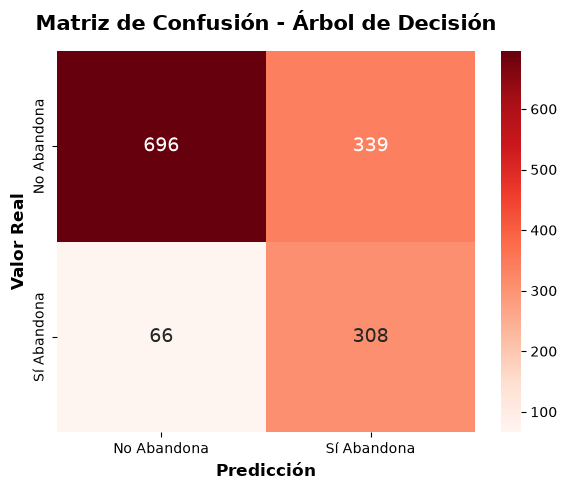

In [50]:
plot_matriz_confusion(y_clf_test, y_pred_dtc, nombre_modelo="Árbol de Decisión")

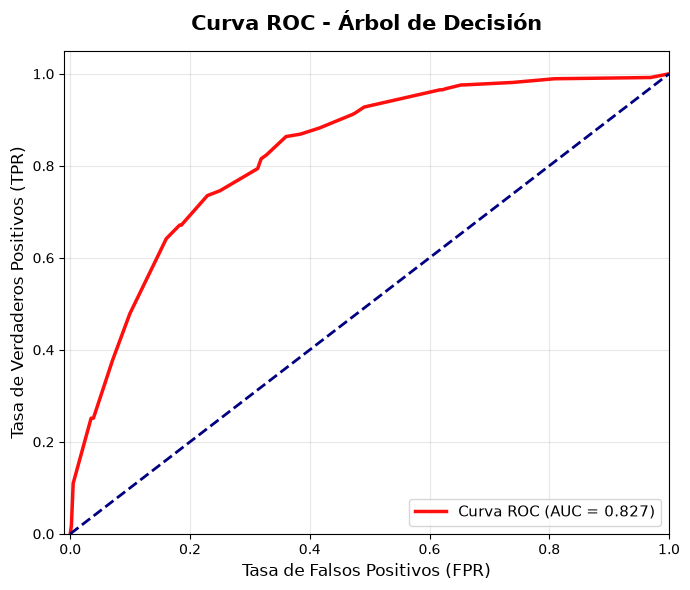

In [51]:
y_proba_dtc = pipeline_final_dtc.predict_proba(X_clf_test)[:, 1]
plot_curva_roc(y_clf_test, y_proba_dtc, nombre_modelo="Árbol de Decisión")

## **3.2 Aprendizaje Supervisado: Modelos de Regresión**

### **3.2.1 Selección de Variables Predictoras**

#### **División de los datos**

In [52]:
# Separar características predictoras y variable objetivo
X_reg = df_regresion.drop(
    columns=['tenure', 'customerID_Hash', 'Churn']
)

y_reg = df_regresion['tenure']

# División de entrenamiento y prueba
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

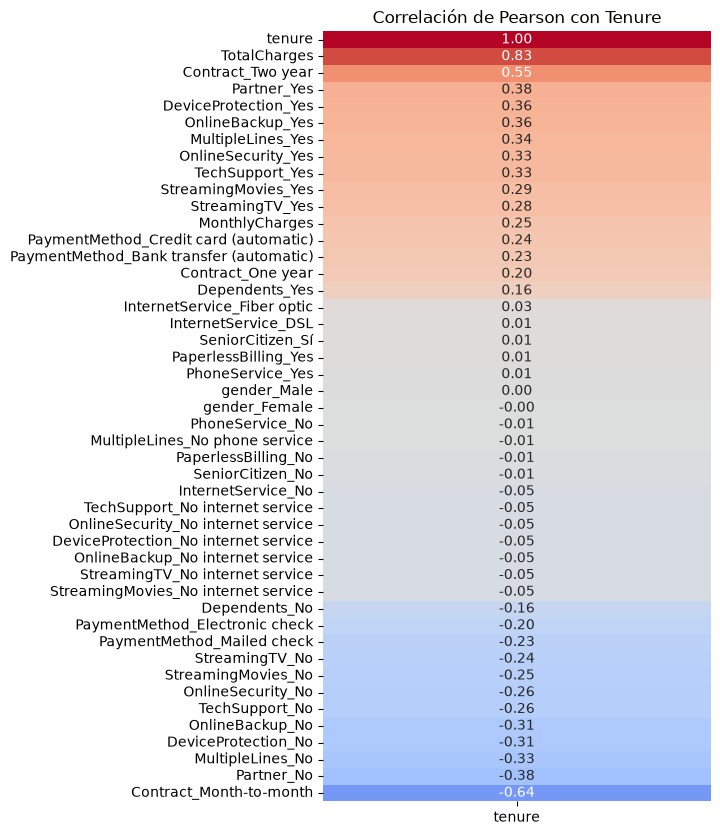

In [53]:
# Crear dataset auxiliar exclusivamente para el análisis de correlación
df_corr_train = X_reg_train.copy()

# Incorporar la variable objetivo de entrenamiento
df_corr_train['tenure'] = y_reg_train

# Variables que se analizarán
vars_analisis_reg = [
    'tenure',
    'TotalCharges',
    'MonthlyCharges',
    'InternetService',
    'TechSupport',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'gender',
    'SeniorCitizen',
    'PaperlessBilling',
    'Partner',
    'Dependents',
    'PhoneService',
    'Contract',
    'StreamingTV',
    'StreamingMovies',
    'PaymentMethod'
]

# Codificar variables categóricas para el análisis
df_dummies = pd.get_dummies(
    df_corr_train[vars_analisis_reg],
    drop_first=False,
    dtype=int
)

# Calcular correlaciones
matriz_corr = df_dummies.corr(method='pearson')

# Ordenar correlaciones respecto a tenure
corr_target = matriz_corr[['tenure']].sort_values(
    by='tenure',
    ascending=False
)

# Visualizar
plt.figure(figsize=(5, 10))

sns.heatmap(
    corr_target,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    cbar=False
)

plt.title('Correlación de Pearson con Tenure', fontsize=12)
plt.show()

Construcción de listados para preprocesamiento:
- Se utilizó el coeficiente de correlación de Pearson para medir la fuerza y dirección de la relación entre las distintas variables (cuantitativas y cualitativas codificadas) y la variable objetivo (tenure), seleccionando así los predictores con mayor o moderado impacto para el modelo.

In [54]:
# Características numéricas para regresión
numericas_reg = [
    'TotalCharges',
    'MonthlyCharges'
]

# Características categóricas binarias
categoricas_binarias_reg = [
    'Partner',
    'DeviceProtection',
    'OnlineSecurity',
    'OnlineBackup',
    'Dependents',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# Características categóricas nominales
categoricas_nominales_reg = [
    'InternetService',
    'PaymentMethod'
]

# Características categóricas ordinales
categoricas_ordinales_reg = [
    'Contract'
]

jerarquia_contrato_reg = [
    ['Month-to-month', 'One year', 'Two year']
]

### **3.2.2 Modelo de Regresión Lineal**
Variable Objetivo: `Tenure`

In [55]:
def crear_preprocesador_regresion(escalar=False):

    # Pipeline numérico
    pasos_numericos = [
        ('imputer', SimpleImputer(strategy='mean'))
    ]

    if escalar:
        pasos_numericos.append(
            ('scaler', MinMaxScaler())
        )

    pipeline_num_reg = Pipeline(pasos_numericos)

    # Pipeline categórico nominal
    pipeline_nom_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    # Pipeline categórico binario
    pipeline_bin_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    # Pipeline categórico ordinal
    pipeline_ord_reg = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            categories=jerarquia_contrato_reg,
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ])

    # Transformador de columnas
    preprocesador = ColumnTransformer(
        transformers=[
            ('num', pipeline_num_reg, numericas_reg),
            ('cat_nom', pipeline_nom_reg, categoricas_nominales_reg),
            ('cat_bin', pipeline_bin_reg, categoricas_binarias_reg),
            ('cat_ord', pipeline_ord_reg, categoricas_ordinales_reg)
        ],
        remainder='drop'
    )

    return preprocesador


# Crear instancias independientes para cada modelo
preprocesador_reg_lineal = crear_preprocesador_regresion(escalar=True)

preprocesador_reg_arbol = crear_preprocesador_regresion(escalar=False)

#### **Pipeline de regresión lineal**

In [56]:
pipeline_reg_lineal = Pipeline(steps=[
    ('preprocesador', preprocesador_reg_lineal),
    ('modelo', LinearRegression())
])

- Se utilizó el algoritmo de **Regresión Lineal** (LinearRegression) debido a su capacidad para modelar la relación entre las variables explicativas (X) y la variable objetivo (Y), trazando la linea que mejor se ajusta a los datos para predecir su comportamiento de forma directa e interpretable.

#### **Entrenamiento y Evaluación RL**

In [57]:
# Regresión lineal
pipeline_reg_lineal.fit(X_reg_train, y_reg_train)
y_pred_reg_lineal = pipeline_reg_lineal.predict(X_reg_test)

#### **Visualizar métricas**

In [58]:
r2 = r2_score(y_reg_test, y_pred_reg_lineal)
mse = mean_squared_error(y_reg_test, y_pred_reg_lineal)
mae = mean_absolute_error(y_reg_test, y_pred_reg_lineal)
rmse = mse ** 0.5
print(f"R-squared: {r2:.4f}")
print(f"MAE: {mae}")


R-squared: 0.8666
MAE: 7.101979251788232


Comprobar como los puntos de predicción se ajustan a la línea de identidad (y=x) en un gráfico de dispersión. Esto nos permite visualizar qué tan bien el modelo está prediciendo los valores de Tenure en comparación con los valores reales.


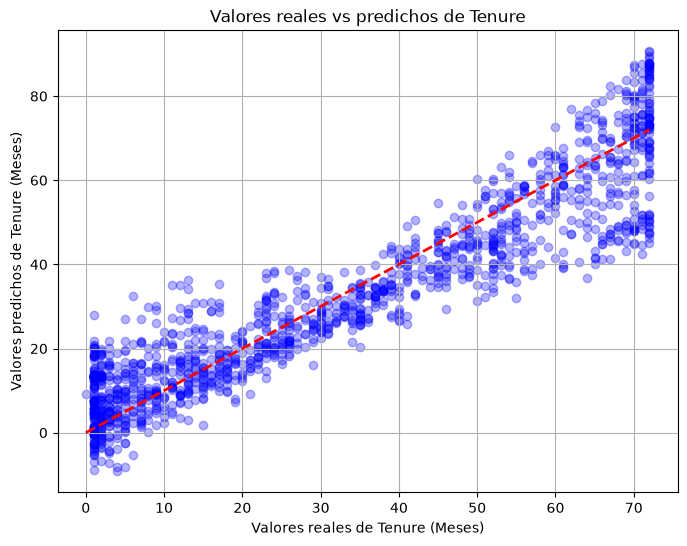

In [59]:
plt.figure(figsize=(8, 6))
plt.scatter(y_reg_test, y_pred_reg_lineal, alpha=0.3, color="blue")
plt.plot([y_reg_test.min(), y_reg_test.max()],[y_reg_test.min(), y_reg_test.max()], 'r--', lw=2)
plt.xlabel("Valores reales de Tenure (Meses)")
plt.ylabel("Valores predichos de Tenure (Meses)")
plt.title("Valores reales vs predichos de Tenure")
plt.grid()
plt.show()

Resultado de las métricas de Regresión Lineal: 
- R2 = 0.87: El modelo de regresión lineal logra explicar el 87.67% de la variabilidad de la permanencia del cliente (tenure) a partir del conjunto de variables predictoras que se seleccionaron.
- MAE = 6.7: En promedio, las predicciones del modelo se equivocan por 6.8 meses aprox respecto al valor real de permanencia del cliente.

### **3.2.3 Modelo de Árbol de Decisión de Regresión Lineal**
Variable objetivo: Tenure

In [60]:
pipeline_reg_arbol = Pipeline(steps=[
    ('preprocesador', preprocesador_reg_arbol),
    ('modelo', DecisionTreeRegressor(
        max_depth = 5,
        random_state=42
    ))
])

- Se seleccionó un Árbol de Decisión (Decision Tree) debido a su capacidad para genera reglas simples de tipo "Si ocurre X, entonces Y", fáciles de explicar a perfiles no técnicos.
- Se limitó la profundidad máxima del árbol a 4 niveles (max_depth = 4) con un número mínimo de 10 muestras (min_sample_leaf=10). Esto evita el sobreajuste (Overfitting) al no memorizar el ruido de los datos, manteniendo el modelo simple e interpretable para la toma de decisiones. 
- Mantenemos la aleatoriedad del algoritmo (random_state) para asegurar que los resultados sean completamente replicables.

In [61]:
# Árbol de decisión
pipeline_reg_arbol.fit(X_reg_train, y_reg_train)
y_pred_reg_arbol = pipeline_reg_arbol.predict(X_reg_test)

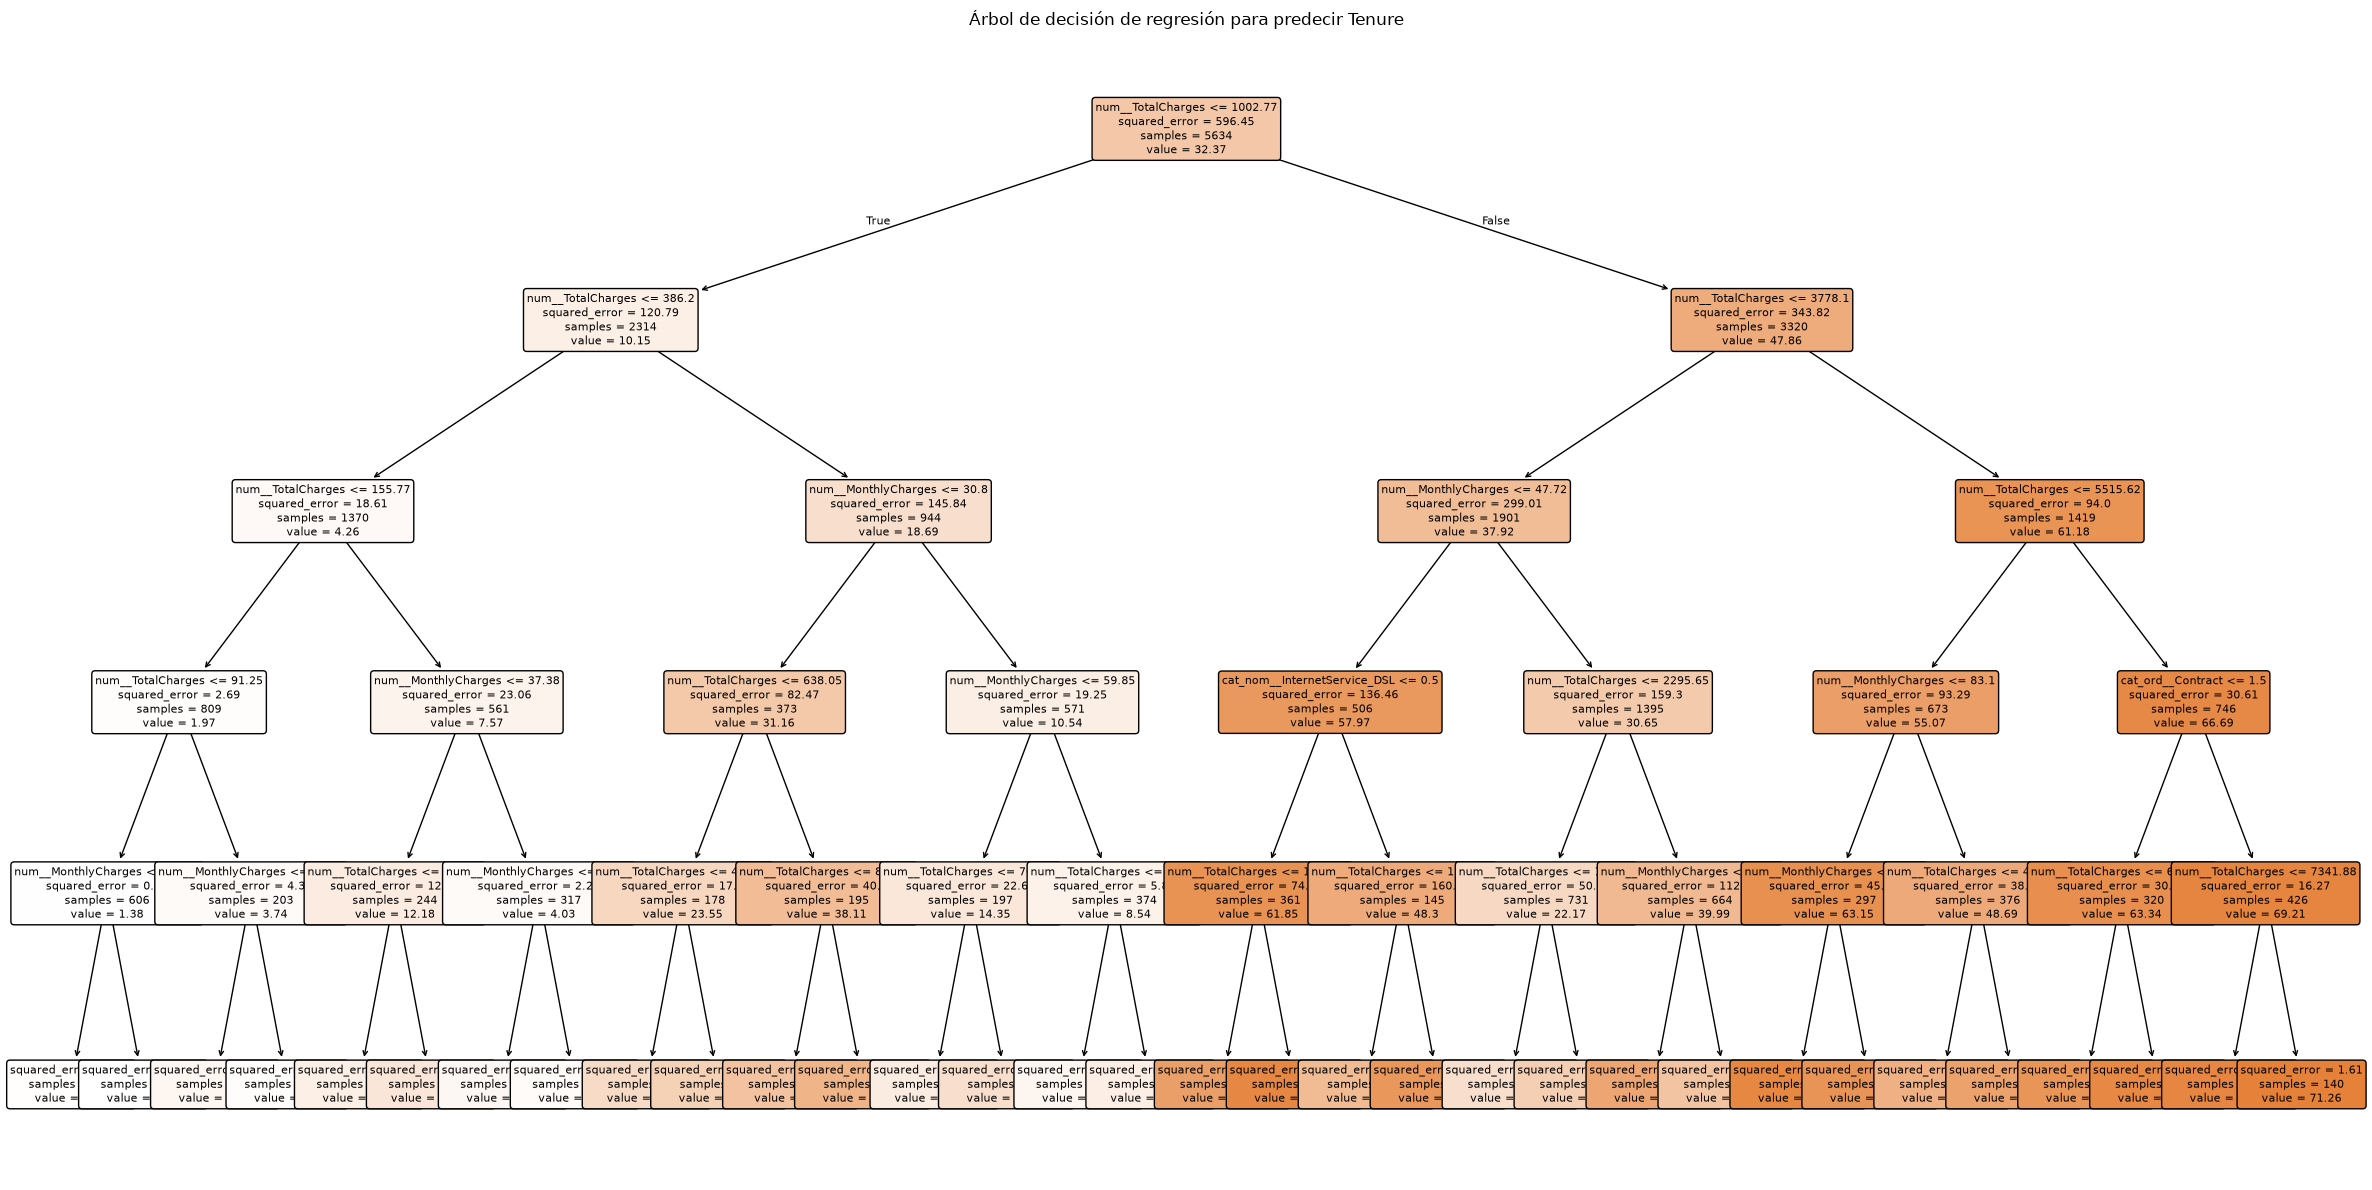

In [62]:
modelo_arbol = pipeline_reg_arbol.named_steps["modelo"]
nombres_variables = pipeline_reg_arbol.named_steps["preprocesador"].get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    modelo_arbol,
    feature_names=nombres_variables,
    filled=True,
    rounded=True,
    fontsize=8,
    precision=2
)
plt.title("Árbol de decisión de regresión para predecir Tenure")
plt.tight_layout()
plt.show()

In [63]:
r2 = r2_score(y_reg_test, y_pred_reg_arbol)
mae = mean_absolute_error(y_reg_test, y_pred_reg_arbol)

print(f"R-squared: {r2:.4f}")
print(f"MAE: {mae}")

R-squared: 0.9624
MAE: 3.3719378156124797


Conclusión de Métricas del Árbol de Decisión

- R2 = 0.9262: El Árbol de Decisión logra explicar el 92.62% de la variabilidad o comportamiento de la antigüedad del cliente (tenure) a partir del tipo de contrato, cobros y servicios contratados.

- MAE = 4.71: En promedio, las predicciones del modelo se equivocan por 4.71 meses (aprox, 4 meses y 21 días) respecto al tiempo real que lleva el cliente en la compañia.


## **3.3 Aprendizaje Supervisado: Modelos de Ensamble**

## **3.4 Aprendizaje No Supervisado: Modelo de Segmentación**

### **3.4.1 Selección de variables segmentadoras**

In [64]:
# Características numéricas para segmentación
numericas_seg = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Características categóricas para segmentación
categoricas_seg = [
    "Partner",
    "Dependents",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

### **3.4.2 Modelo de segmentación KMeans**

In [65]:
# Seleccionar características desde el dataset exclusivo de segmentación
X_seg = df_segmentacion[
    numericas_seg + categoricas_seg
].copy()

# Pipeline numérico
pipeline_numerico_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

# Pipeline categórico
pipeline_categorico_seg = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Preprocesador exclusivo de segmentación
preprocesador_segmentacion = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerico_seg, numericas_seg),
        ('cat', pipeline_categorico_seg, categoricas_seg)
    ],
    remainder='drop'
)

# Transformar los datos
matriz_limpia = preprocesador_segmentacion.fit_transform(X_seg)

# Crear DataFrame con las características transformadas
df_limpia = pd.DataFrame(
    matriz_limpia,
    columns=preprocesador_segmentacion.get_feature_names_out(),
    index=X_seg.index
)

df_limpia.head()

,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,...,cat__TechSupport_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,0.013889,0.115423,0.003437,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.472222,0.385075,0.217564,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.027778,0.354229,0.012453,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.625000,0.239303,0.211951,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.027778,0.521891,0.017462,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [66]:
inercias = []
rango_k = range(2, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_limpia)
    inercias.append(kmeans.inertia_)

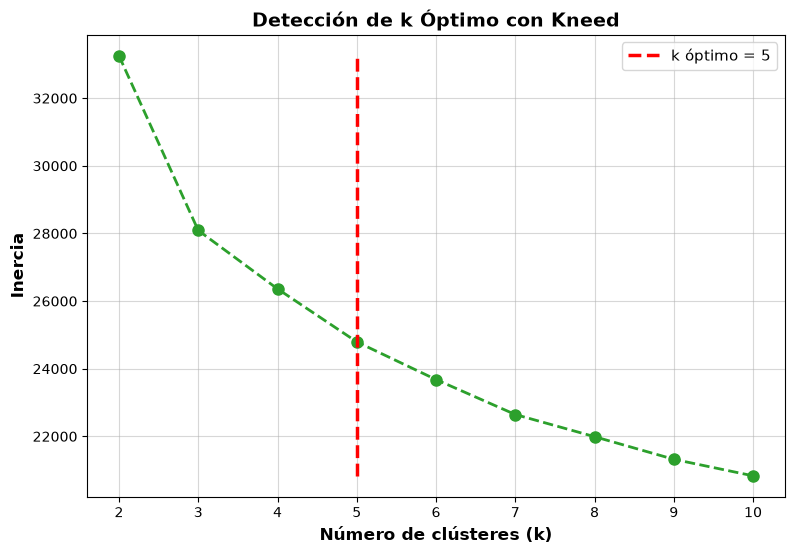

Número óptimo de clústeres: 5


In [67]:
kl = KneeLocator(rango_k, inercias, curve="convex", direction="decreasing")
k_optimo = kl.elbow
plt.figure(figsize=(9, 6))
plt.plot(rango_k, inercias, marker='o', linestyle='--', color='#2ca02c', linewidth=2, markersize=8)

plt.vlines(
    x=k_optimo,
    ymin=min(inercias),
    ymax=max(inercias),
    colors='red',
    linestyles='--',
    linewidth=2.5,
    label=f'k óptimo = {k_optimo}'
)

plt.title("Detección de k Óptimo con Kneed", fontsize=14, fontweight="bold")
plt.xlabel("Número de clústeres (k)", fontsize=12, fontweight="bold")
plt.ylabel("Inercia", fontsize=12, fontweight="bold")
plt.xticks(rango_k)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.5)
plt.show()

print(f"Número óptimo de clústeres: {k_optimo}")

In [68]:
kmeans_final = KMeans(n_clusters= k_optimo, random_state=42, n_init=10)
etiquetas_clusters = kmeans_final.fit_predict(df_limpia)
print(f"Inercia del modelo (k={k_optimo}): {kmeans_final.inertia_:.2f}")

Inercia del modelo (k=5): 24794.38


In [69]:
score = silhouette_score(df_limpia, etiquetas_clusters)

print(f"Silhouette Score: {score:.4f}")

Silhouette Score: 0.1887


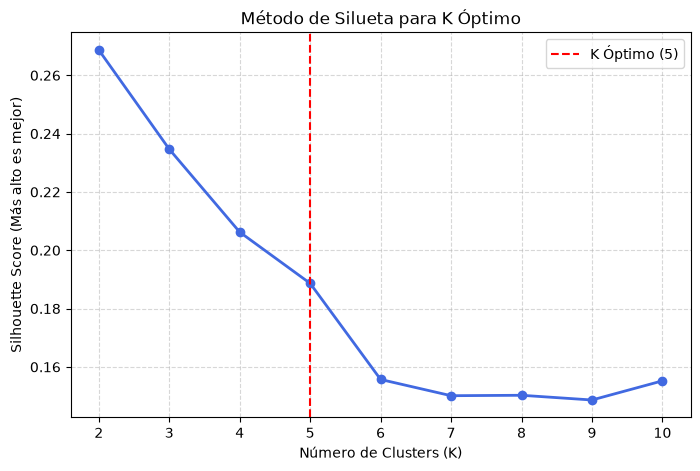

In [70]:
rango_k = range(2, 11)
scores = []

for k in rango_k:
    modelo_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_temp = modelo_temp.fit_predict(df_limpia)
    score_temp = silhouette_score(df_limpia, etiquetas_temp)
    scores.append(score_temp)

plt.figure(figsize=(8, 5))
plt.plot(rango_k, scores, marker='o', color='royalblue', linewidth=2)
plt.axvline(x=k_optimo, color='red', linestyle='--', label=f'K Óptimo ({k_optimo})')

plt.title('Método de Silueta para K Óptimo')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Silhouette Score (Más alto es mejor)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* Bajo índice de silueta, por tanto se infiere solapamiento de los clusters y poca separación de los mismos.
* Inercia media-baja, por tanto se infiere un agrupamiento de cluster regular, ni tan bueno, ni tan malo. 

### **3.4.3 PCA**

In [71]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(df_limpia)

print("Varianza explicada:", pca.explained_variance_ratio_)

Varianza explicada: [0.25603055 0.16384588]


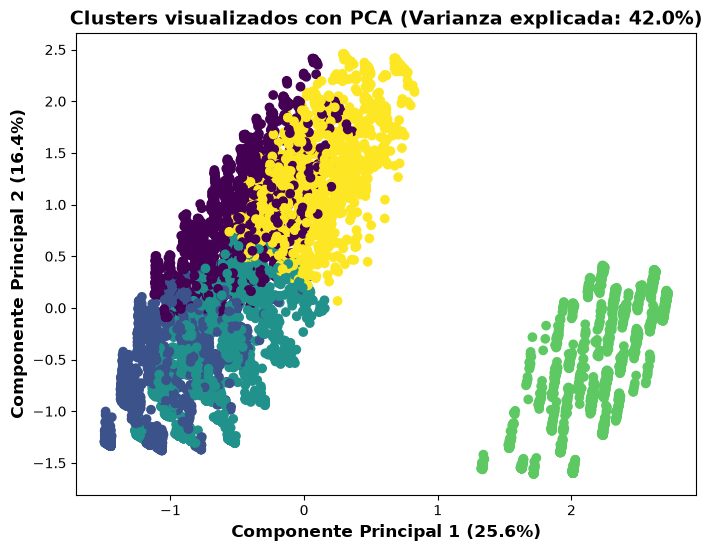

In [72]:
# Calcular porcentaje de varianza explicada
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_acumulada = var_pc1 + var_pc2

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca.iloc[:, 0],
    X_pca.iloc[:, 1],
    c=etiquetas_clusters,
    cmap="viridis"
)

plt.xlabel(
    f"Componente Principal 1 ({var_pc1:.1f}%)",
    fontsize=12,
    fontweight="bold"
)

plt.ylabel(
    f"Componente Principal 2 ({var_pc2:.1f}%)",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    f"Clusters visualizados con PCA (Varianza explicada: {var_acumulada:.1f}%)",
    fontsize=14,
    fontweight="bold"
)

plt.show()

* Uso de PCA con varianza explicada del 54% aproximadamente, por tanto se infiere que al menos la mitad de información se refleja en el gráfico mediante sus componentes.
* Observaciones: 
    - Uno de los cluster bien separado y relativamente compacto.
    - Solapamiento claro en los otros dos cluster.

In [73]:
# Crear una copia para almacenar los resultados de segmentación
df_segmentacion_resultados = df_segmentacion.copy(deep=True)

# Incorporar las etiquetas de los clusters
df_segmentacion_resultados["clusters"] = etiquetas_clusters

### **3.4.4 Aplicación al problema de negocio**

#### **Porcentajes de abandono por cluster**

Porcentaje de abandono (Churn) por Cluster:


Churn,No,Yes
clusters,,
0,78.1,21.9
1,43.0,57.0
2,69.2,30.8
3,92.6,7.4
4,94.8,5.2


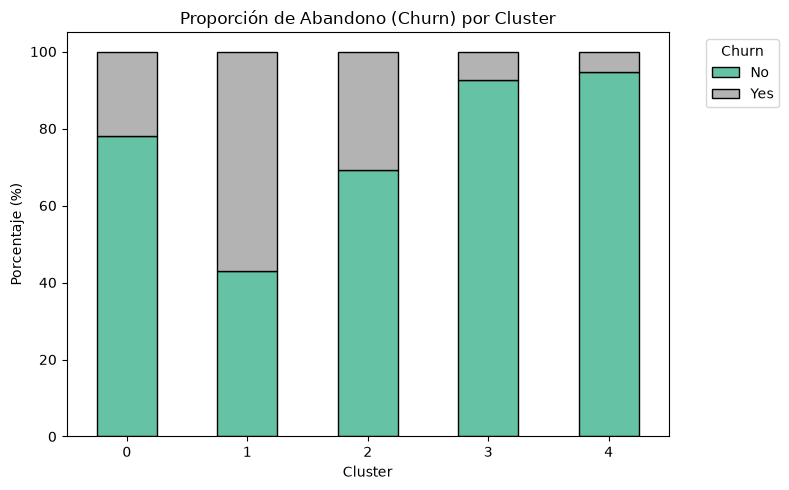

In [74]:
# Calcular porcentaje de abandono por cluster
porcentaje_churn = pd.crosstab(
    df_segmentacion_resultados['clusters'],
    df_segmentacion_resultados['Churn'],
    normalize='index'
) * 100

print("Porcentaje de abandono (Churn) por Cluster:")
display(porcentaje_churn.round(1))

porcentaje_churn.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='Set2', edgecolor='black')

plt.title('Proporción de Abandono (Churn) por Cluster')
plt.xlabel('Cluster')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

* Clusters 0 y 2 con bajo porcentaje de abandono
* Cluster 1 con un alto porcentaje de abandono, por tanto podría considerarse un candidato para fijación con estrategias de retención.

#### **Perfilamiento de los clusters**

In [75]:
# Identificar variables numéricas para el perfilamiento
cols_numericas = df_segmentacion_resultados.select_dtypes(
    include=np.number
).columns.drop(
    ['clusters', 'Churn'],
    errors='ignore'
)

# Identificar variables categóricas para el perfilamiento
cols_categoricas = df_segmentacion_resultados.select_dtypes(
    include=['object', 'category', 'bool', 'str']
).columns.drop(
    ['customerID_Hash', 'gender', 'Churn'],
    errors='ignore'
)

print("\nPERFIL NUMÉRICO")

perfil_num = (
    df_segmentacion_resultados
    .groupby('clusters')[cols_numericas]
    .mean()
    .round(2)
)

display(perfil_num)

print("\nPERFIL CATEGÓRICO")

perfil_cat = (
    df_segmentacion_resultados
    .groupby('clusters')[cols_categoricas]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
)

display(perfil_cat)


PERFIL NUMÉRICO


,tenure,MonthlyCharges,TotalCharges
clusters,,,
0,52.92,100.16,5354.48
1,17.85,84.76,1568.43
2,17.07,49.70,882.83
3,30.55,21.08,662.60
4,51.36,69.03,3640.41



PERFIL CATEGÓRICO


,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
clusters,,,,,,,,,,,,,,,
0,No,Yes,No,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,One year,Yes,Electronic check
1,No,No,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
2,No,No,No,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
3,No,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check
4,No,Yes,Yes,Yes,Yes,DSL,Yes,Yes,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic)


* Cluster 0: Cliente análogo y de bajo impacto.
    - Usuarios de tecnología antigua, fidelizados con contratos estables, pero que no adoptan nuevas tecnologías.
* Cluster 1: Cliente Digitales de banda ancha y alto riesgo de fuga.
    - Usuarios de fibra óptica, pero no tienen lealtad a la marca ni consumen servicios extra.
* Cluster 2: Cliente Multi-Servicio y consolidado.
    - Usuarios que consumen la gama completa de servicios y están profundamente integrados en el ecosistema de la empresa.